# Air Quality Analysis and 7-Day AQI Forecasting in Denpasar, Bali

This notebook analyses daily air quality in Denpasar from August 2022 to October 2026 and builds a
machine learning model that forecasts the US Air Quality Index (AQI) for the next seven days. It
follows the CRISP-DM framework:

| # | Section | CRISP-DM phase | Purpose |
|---|---|---|---|
| 1 | Project Overview | Business Understanding | Context and motivation |
| 2 | Business Understanding | Business Understanding | Problem statements, goals, situation assessment, success criteria, and solution approach |
| 3 | Setup | — (technical setup) | Libraries, minimum versions, and project-wide configuration |
| 4 | Data Understanding | Data Understanding | Collect, describe, verify, and explore the data |
| 5 | Data Preparation | Data Preparation | Select, construct, and format the data, and fix the test design |
| 6 | Modelling | Modeling | Select techniques, then build and assess the candidate models |
| 7 | Evaluation | Evaluation | Held-out test assessment, business criteria, process review, and next steps |
| 8 | Forecasting and Export | Deployment | Final refit, 7-day forecast, and dashboard exports |
| 9 | Conclusion and Recommendations | Evaluation (summary) | Outcomes against the goals and prescriptive actions |

CRISP-DM is iterative, and this notebook deviates from the textbook task order in two deliberate
places. Both are marked where they occur:

* **Preliminary integration and cleaning (4.4) come before the EDA.** These are Data Preparation
  tasks, but exploration needs a merged and continuous daily series.
* **The test design (5.2 and 5.4) is fixed during Data Preparation.** This is a Modeling task, but
  fixing the split early lets every fitted preparation step use the training split only.

## 1. Project Overview

**Bali's clean-air image is both a public health asset and an economic one, and protecting it takes
evidence.**

Air pollution is one of the largest environmental risks to human health. The World Health
Organization (WHO) estimates that air pollution causes about seven million premature deaths
worldwide every year. In 2021 it tightened its annual guideline for fine particulate matter (PM2.5)
to 5 µg/m³ (World Health Organization, 2021).

Indonesia is heavily exposed. Virtually all of its 276 million people live in areas where annual
PM2.5 exceeds the WHO guideline, and exposure is 61.7% higher than in 1998. Meeting the guideline
would add 1.3 years to the life of the average Indonesian (Energy Policy Institute at the
University of Chicago [EPIC], 2025). The damage goes beyond the lungs: a national study of more
than 640,000 Indonesians found that every 10 µg/m³ increase in PM2.5 raised the odds of diabetes by
9% (Suryadhi et al., 2020).

Bali is often seen as a clean-air destination, yet the pressure on its capital, Denpasar, keeps
rising. The island recorded a record 6.95 million foreign tourist arrivals in 2025, 9.72% more than
in 2024 (Badan Pusat Statistik Provinsi Bali, 2026). Every additional visitor adds traffic, energy
use, and waste.

Waste is already a proven trigger of pollution episodes:

* **October 2023:** a fire spread across nearly half of the 32-hectare Suwung landfill in southern
  Denpasar. The city declared an emergency, set up health posts, and distributed masks to residents
  of the surrounding neighbourhoods (Rhismawati, 2023a, 2023b; Suadnyana, 2023).
* **2026:** the phased closure of the Suwung landfill left trash piling up across the city, and
  residents reported burning household waste in the open (Erviani, 2026).

The encouraging news is that much of this pollution is local, and therefore controllable. During
Nyepi, the Balinese Day of Silence, almost all activity stops:

* Total suspended particulate concentrations fell by 73–78% at urban sites in Bali, and
  particulate levels were negatively correlated with air temperature and wind speed (Nuraini et
  al., 2019).
* A later study measured a drop of about 47% in PM2.5 during Nyepi 2022 relative to the 2020–2022
  average, together with lower CO and NO₂ (Nuryanto et al., 2024).

In short, human activity sets how much pollution is emitted, and the weather decides how much of it
stays in the air.

**What this project delivers.** Using daily air quality and weather data for Denpasar from August
2022 to October 2026, this notebook answers three practical questions for decision-makers:

1. How has air quality evolved?
2. Which conditions drive high-AQI days?
3. What are the next seven days likely to bring?

### 1.1 References

Every source below was published in 2019 or later. Citations follow APA 7th edition.

#### News articles

Erviani, N. K. (2026, April 27). Bali trash issues raise concerns after landfill closure. *The
Jakarta Post*; republished by Asia News Network.
https://asianews.network/bali-trash-issues-raise-concerns-after-landfill-closure/

Rhismawati, N. L. (2023a, October 12). BPBD Denpasar: Hampir separuh TPA Suwung terbakar [Denpasar
disaster agency: Nearly half of the Suwung landfill has burned]. *ANTARA News Bali*.
https://bali.antaranews.com/berita/327429/bpbd-denpasar-hampir-separuh-tpa-suwung-terbakar

Rhismawati, N. L. (2023b, October 13). Denpasar keluarkan status tanggap darurat bencana kebakaran
di TPA Suwung [Denpasar declares a fire emergency at the Suwung landfill]. *ANTARA News Bali*.
https://bali.antaranews.com/berita/327540/denpasar-keluarkan-status-tanggap-darurat-bencana-kebakaran-di-tpa-suwung

Suadnyana, I. W. S. (2023, October 13). Polisi bagi-bagi masker ke warga terdampak kebakaran TPA
Suwung [Police distribute masks to residents affected by the Suwung landfill fire]. *detikBali*.
https://www.detik.com/bali/berita/d-6981222/polisi-bagi-bagi-masker-ke-warga-terdampak-kebakaran-tpa-suwung

#### Official statistics, reports, and regulations

Badan Pusat Statistik Provinsi Bali. (2026, February 2). *Bali's foreign arrivals Jan–Dec 2025 rise,
with Australia remaining the largest contributor overall* [Press release].
https://bali.bps.go.id/en/news/2026/02/02/347/bali-s-foreign-arrivals-jan-dec-2025-rise--with-australia-remaining-the-largest-contributor-overall-.html

Energy Policy Institute at the University of Chicago. (2025). *Air Quality Life Index: Indonesia
fact sheet*. https://aqli.epic.uchicago.edu/hi/files/Indonesia%20FactSheet_2025.pdf

Kementerian Lingkungan Hidup dan Kehutanan. (2020). *Peraturan Menteri Lingkungan Hidup dan
Kehutanan Nomor 14 Tahun 2020 tentang Indeks Standar Pencemar Udara* [Regulation of the Minister of
Environment and Forestry No. 14 of 2020 on the Air Pollutant Standard Index].
https://peraturan.bpk.go.id/Details/163466/p

World Health Organization. (2021). *WHO global air quality guidelines: Particulate matter (PM2.5 and
PM10), ozone, nitrogen dioxide, sulfur dioxide and carbon monoxide*.
https://www.who.int/publications/i/item/9789240034228

#### Scientific papers

Cerqueira, V., Torgo, L., & Mozetič, I. (2020). Evaluating time series forecasting models: An
empirical study on performance estimation methods. *Machine Learning, 109*(11), 1997–2028.
https://doi.org/10.1007/s10994-020-05910-7

Chianese, E., & Riccio, A. (2026). Multi-model ensemble approaches in air quality prediction: A
comprehensive review from chemical transport models to hybrid machine learning. *Atmosphere,
17*(7), Article 689. https://doi.org/10.3390/atmos17070689

Hewamalage, H., Ackermann, K., & Bergmeir, C. (2023). Forecast evaluation for data scientists:
Common pitfalls and best practices. *Data Mining and Knowledge Discovery, 37*(2), 788–832.
https://doi.org/10.1007/s10618-022-00894-5

Inness, A., Ades, M., Agustí-Panareda, A., Barré, J., Benedictow, A., Blechschmidt, A.-M.,
Dominguez, J. J., Engelen, R., Eskes, H., Flemming, J., Huijnen, V., Jones, L., Kipling, Z.,
Massart, S., Parrington, M., Peuch, V.-H., Razinger, M., Remy, S., Schulz, M., & Suttie, M. (2019).
The CAMS reanalysis of atmospheric composition. *Atmospheric Chemistry and Physics, 19*(6),
3515–3556. https://doi.org/10.5194/acp-19-3515-2019

Kolassa, S. (2026). The symmetric mean absolute percentage error: Unnecessary or dangerous.
*Forecasting, 8*(2), Article 24. https://doi.org/10.3390/forecast8020024

Lacima, A., Petetin, H., Soret, A., Bowdalo, D., Jorba, O., Chen, Z., Méndez Turrubiates, R. F.,
Achebak, H., Ballester, J., & Pérez García-Pando, C. (2023). Long-term evaluation of surface air
pollution in CAMSRA and MERRA-2 global reanalyses over Europe (2003–2020). *Geoscientific Model
Development, 16*(9), 2689–2718. https://doi.org/10.5194/gmd-16-2689-2023

Méndez, M., Merayo, M. G., & Núñez, M. (2023). Machine learning algorithms to forecast air quality:
A survey. *Artificial Intelligence Review, 56*, 10031–10066.
https://doi.org/10.1007/s10462-023-10424-4

Nuraini, T. A., Satyaningsih, R., Permana, D. S., Anggraeni, R., & Aldrian, E. (2019). Comparison
of total suspended particulate (TSP) measurement in urban and suburban areas of Bali during Nyepi
Day 2015. *Forum Geografi, 33*(2), 173–183. https://doi.org/10.23917/forgeo.v33i2.8670

Nuryanto, D. E., Permana, D. S., Hidayanto, N., Rizal, J., Heriyanto, E., Harapan, F. A.,
Fajariana, Y., & Komalasari, K. E. (2024). The effect of human activities on Bali's Silent Day
(Nyepi) in 2022. *E3S Web of Conferences, 485*, Article 06010.
https://doi.org/10.1051/e3sconf/202448506010

Suryadhi, M. A. H., Suryadhi, P. A. R., Abudureyimu, K., Ruma, I. M. W., Calliope, A. S., Wirawan,
D. N., & Yorifuji, T. (2020). Exposure to particulate matter (PM2.5) and prevalence of diabetes
mellitus in Indonesia. *Environment International, 140*, Article 105603.
https://doi.org/10.1016/j.envint.2020.105603

Wu, C., Li, K., & Bai, K. (2020). Validation and calibration of CAMS PM2.5 forecasts using in situ
PM2.5 measurements in China and United States. *Remote Sensing, 12*(22), Article 3813.
https://doi.org/10.3390/rs12223813

## 2. Business Understanding

**Acting late is expensive.** Once the AQI has already turned unhealthy, only damage control is
left: warnings arrive after people have been exposed, and enforcement starts after the smoke has
spread.

As tourism and urban activity grow, air quality has become a strategic issue for local government,
public health agencies, and the tourism sector. For Denpasar, the gateway to one of the world's
best-known island destinations, the ability to monitor, explain, and anticipate air quality has
three benefits:

* it protects residents' health;
* it safeguards Bali's reputation as a clean and healthy destination;
* it grounds environmental policy in evidence.

Hourly air quality estimates and daily weather records already exist, but in raw form they are too
voluminous to guide decisions. This project turns them into three decision tools:

1. **A baseline** that shows when the risk is highest.
2. **An analysis of the conditions** behind high-AQI days.
3. **A 7-day forecast** that lets agencies act **before** air quality deteriorates, not after.

### 2.1 Problem Statements

1. **There is no consolidated picture of how Denpasar's air quality has evolved.**
   Air quality data arrive hourly and in large volumes, so it is hard to see which years, months,
   or seasons carry the highest risk.
   *What is at stake:* monitoring stays reactive instead of concentrating resources on high-risk
   periods.

2. **The conditions behind poor air quality are not quantified.**
   It is unclear which pollutants move most closely with the AQI, and which weather conditions,
   such as low rainfall or weak wind, favour pollutant build-up.
   *What is at stake:* mitigation stays generic instead of targeting the sources and conditions
   that matter.

3. **There is no reliable short-term forecast.**
   Without a forecast for the coming days, public health advisories are issued only after the AQI
   has already deteriorated. It is also unclear which tree-based ensemble strategy, bagging (Random
   Forest) or boosting (Gradient Boosting), captures Denpasar's daily AQI dynamics more accurately.
   *What is at stake:* advisories reach the public only after exposure has happened.

### 2.2 Goals

Each goal answers one problem statement and is measured by the criteria in Section 2.4 (IDs in
brackets).

1. **Establish an air quality baseline for Denpasar (August 2022 – October 2026)** [B1, D1].
   Quantify:
   * the annual mean AQI and its year-over-year change;
   * the share of days with AQI above 100;
   * the difference between the dry season (April–October) and the wet season (November–March).

   Characterise the trend, seasonality, and day-to-day persistence of the AQI.

2. **Identify the variables most strongly associated with the AQI** [B2, D2].
   Rank pollutants and weather variables by their Spearman correlation with same-day and next-day
   AQI, and confirm the ranking with the permutation importance of the forecasting model. Translate
   the results into monitoring priorities and weather-based early-warning signals.

3. **Produce a reliable 7-day daily AQI forecast** [B3, D3–D5].
   Compare Gradient Boosting and Random Forest, and select the candidate with the lowest
   walk-forward cross-validation RMSE. On the held-out test period, the selected model must:
   * beat the persistence and climatology benchmarks on RMSE and MAE;
   * reach a mean sMAPE of 15% or less across the seven horizons;
   * place more forecasts in the correct AQI category than the best benchmark.

   The final model forecasts AQI for days t+1 to t+7, each with an uncertainty band and an AQI
   category.

### 2.3 Situation Assessment

**Stakeholders and the decisions this project supports**

| Stakeholder | Decision supported | Outputs used |
|---|---|---|
| Denpasar City Government and the Bali Provincial Environment Agency (DLH) | Mitigation priorities and the timing of enforcement | Baseline KPIs, variable ranking, seasonal risk windows |
| Health services (Dinas Kesehatan and community health centres) | Timing and content of public health advisories | 7-day forecast with AQI categories |
| Tourism stakeholders | Visitor communication and protection of the destination's image | Dashboard and forecast |

**Resources**

* **Data:** three Kaggle datasets covering 31 Indonesian cities from August 2022 to October 2026.
  The Denpasar subset has 1,548 days.
* **Tools:** Python with pandas, scikit-learn, statsmodels, and Optuna, run in a Kaggle notebook
  environment.
* **Deliverables:** this notebook and the datasets that feed the Streamlit dashboard.

**Requirements, assumptions, and constraints**

* **Requirements:** results must be reproducible (fixed seeds and versioned artifacts), free of
  data leakage, and explainable to non-technical audiences.
* **Assumptions:**
  * CAMS estimates are assumed to represent city-level conditions in Denpasar. This is a material
    assumption: evaluations against ground stations report persistent surface biases in CAMS
    reanalyses and forecasts, especially for PM2.5 (Lacima et al., 2023; Wu et al., 2020).
  * Relationships observed in 2022–2026 are assumed to persist into the forecast window.
  * Weather observed on day t is assumed to carry information about the next seven days.
* **Constraints:** the air quality data are model-based estimates from the Copernicus
  Atmosphere Monitoring Service (CAMS) modelling and data-assimilation system (Inness et al., 2019),
  not ground-station measurements. There are no anthropogenic variables such as traffic, tourist arrivals, or
  waste-burning reports. The history covers about four years, and the data have daily resolution
  only.

**Risks and contingencies**

| Risk | Contingency in this notebook |
|---|---|
| CAMS model upgrades shift pollutant levels | Regime flags, a chronological test period after the latest upgrade, and regime-aware metrics |
| Data leakage inflates accuracy | Causal features, a 6-day embargo, train-only fitting, and a single test evaluation |
| Overfitting during tuning | Walk-forward CV, regularised search spaces, and comparison with default baselines |
| Few unhealthy days to learn from | Category accuracy and residual analysis around spikes |
| Correlation mistaken for causation | Explicit caveats in the association analysis |

**Costs and benefits.** A missed pollution spike costs more than an unnecessary advisory, because
it leaves sensitive groups exposed without warning. This asymmetry is why RMSE, which penalises
large errors, is the primary metric, and why the upper P90 band is proposed as an advisory trigger.

### 2.4 Success Criteria and Evaluation Metrics

CRISP-DM separates business success criteria, which judge whether the project helps stakeholders,
from data-mining success criteria, which judge the analytical results. Both are assessed in
Section 7.8.

**Business success criteria**

| ID | Business objective | Success criterion |
|---|---|---|
| B1 | Consolidated view of air quality (Problem Statement 1) | Annual KPIs and seasonal risk windows cover the whole data period and are traceable to the daily data |
| B2 | Targeted mitigation (Problem Statement 2) | The variables most associated with the AQI are ranked and translated into monitoring priorities and weather-based early-warning signals |
| B3 | Proactive advisories (Problem Statement 3) | A daily 7-day forecast with AQI categories is available, and its test-split category accuracy exceeds that of the best naive benchmark |

**Data-mining success criteria**

| ID | Goal | Criterion | Target |
|---|---|---|---|
| D1 | 1 | Baseline KPIs | Annual mean, year-over-year change, share of days above AQI 100, and dry vs. wet difference reported |
| D2 | 2 | Association ranking | Spearman ρ reported for every weather and pollutant variable; top permutation-importance features reported |
| D3 | 3 | Model selection | Lowest walk-forward CV RMSE among the four candidates |
| D4 | 3 | Beats naive benchmarks | Lower RMSE **and** MAE than persistence and climatology on the test split (mean over 7 horizons) |
| D5 | 3 | Relative accuracy | sMAPE ≤ 15% on the test split (mean over 7 horizons) |

Metrics are computed in AQI units, where $y_t$ is the actual AQI, $\hat{y}_t$ the forecast, and $n$
the number of forecasts.

* **RMSE** (primary metric). It penalises large errors more heavily, which matters because a missed
  pollution spike is costlier than a small routine error.
  $\text{RMSE} = \sqrt{\tfrac{1}{n}\sum_{t=1}^{n}(y_t - \hat{y}_t)^2}$
* **MAE.** The average absolute error: "on average, the forecast is off by X AQI points."
  $\text{MAE} = \tfrac{1}{n}\sum_{t=1}^{n}\lvert y_t - \hat{y}_t\rvert$
* **sMAPE.** A scale-free percentage error that non-technical stakeholders can read directly.
  $\text{sMAPE} = \tfrac{100\%}{n}\sum_{t=1}^{n}\dfrac{2\,\lvert y_t - \hat{y}_t\rvert}{\lvert y_t\rvert + \lvert \hat{y}_t\rvert}$
* **Category accuracy.** The share of forecasts that fall in the same US AQI category as the actual
  value. This is the operational view used for health advisories.

**Why sMAPE instead of MAPE.**

* **The problem with MAPE.** The original project plan specified MAPE ≤ 15%. MAPE divides each
  error by the actual value only, so it is unbounded for over-forecasts but capped at 100% for
  under-forecasts. A model that habitually under-predicts can therefore look better than it is.
  That is the wrong incentive when a missed pollution spike is the costliest error. Percentage
  errors need particular care in forecast evaluation (Hewamalage et al., 2023).
* **Why sMAPE fits this data.** sMAPE is bounded and treats over- and under-forecasts more evenly.
  Its best-known failure modes arise when actual values are zero or intermittent (Kolassa, 2026).
  Daily AQI in Denpasar never falls below 15, so those cases do not occur here.
* **Remaining caveat.** sMAPE is still an imperfect measure, which is why RMSE remains the primary
  selection metric.

The criterion was changed after preliminary results were available. Section 7.9 records this as a
point to fix in the next iteration.

### 2.5 Solution Approach

Two complementary approaches address the three goals.

**A. Descriptive and statistical analysis (Goals 1 and 2)**

* **Baseline KPIs:** daily AQI is aggregated per year to obtain the mean, the year-over-year change,
  and the share of days above AQI 100, and per season to compare dry and wet months.
* **Trend and seasonality:** 30-day rolling means, monthly profiles per year, an annual Fourier
  regression, a Kruskal–Wallis test for weekday effects, ACF/PACF analysis, and stationarity tests
  (ADF, KPSS, and Zivot–Andrews).
* **Association analysis:** a Spearman correlation matrix and LOWESS scatter plots relate each
  weather and pollutant variable to same-day and next-day AQI.
* **Presentation:** the clean daily dataset is exported for an interactive Streamlit dashboard with
  KPI cards, trend charts, and seasonal filters.

**B. Direct multi-horizon forecasting with tree-based ensembles (Goal 3)**

* **Framing:** forecasting is recast as supervised regression. Features observed on day t predict
  the AQI on days t+1 to t+7 directly. Gradient Boosting uses one model per horizon
  (`MultiOutputRegressor`), and Random Forest predicts all horizons natively.
* **Causal features:** AQI at t, t−1, and t−2; 7- and 30-day rolling mean, maximum, and standard
  deviation; 3- and 7-day rainfall sums; annual Fourier terms; pollutant and weather values on day t;
  and a flag for the CAMS model regime.
* **Candidates:** Gradient Boosting and Random Forest, each with default hyperparameters (baseline)
  and with hyperparameters tuned by Optuna (TPE sampler with median pruning).
* **Validation:** a chronological 65/15/20 split with a 6-day embargo between splits. Candidates are
  tuned and compared with 10-fold walk-forward cross-validation on train + validation. The test
  split is used only once, to evaluate the selected model.
* **Benchmarks:** persistence (tomorrow equals today) and monthly climatology.
* **Deployment:** the selected configuration is refit on the full labelled history before it
  produces the 7-day forecast.

**Why this design**

* **Machine learning is a proven approach.** It is now mainstream in air quality forecasting, with
  meteorological variables among the most common predictors (Méndez et al., 2023).
* **Tree-based ensembles suit tabular data.** For structured data such as daily pollutant and
  weather records, Random Forest and gradient boosting form a core part of the current state of the
  art (Chianese & Riccio, 2026). They capture threshold effects, are robust to outliers, need little
  preprocessing, and explain their predictions through feature importance.
* **Validation must respect time order.** When a series is exposed to non-stationary shifts, such
  as the CAMS upgrades in this data, out-of-sample schemes that preserve temporal order give the
  most reliable error estimates (Cerqueira et al., 2020). This is why the notebook relies on
  walk-forward cross-validation and a chronological test period instead of random splits.

## 3. Setup (Technical Prerequisites)

This section is not a CRISP-DM phase. It prepares the environment that every later phase relies on.

### 3.1 Libraries and Minimum Versions

All imports live in a single cell, grouped into standard-library and third-party modules. The
notebook relies on a few recent APIs, so the import cell checks minimum versions and stops
immediately with a clear message if an older package is installed.

In [1]:
# Optuna is not included in every base image; install it before the imports below.
%pip install -q "optuna>=4.0"

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ===== Standard library =====
import calendar
import hashlib
import json
import math
import re
import warnings
from collections.abc import Callable, Collection, Mapping, Sequence
from dataclasses import dataclass
from importlib.metadata import version
from itertools import accumulate
from pathlib import Path

# ===== Third-party =====
import joblib
import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
from matplotlib.axes import Axes
from optuna.storages import JournalStorage
from optuna.storages.journal import JournalFileBackend
from scipy.stats import kruskal
from sklearn.base import RegressorMixin
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, root_mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.multioutput import MultiOutputRegressor
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import adfuller, kpss, zivot_andrews

# ===== Minimum versions required by APIs used in this notebook =====
MIN_VERSIONS = {
    "pandas": "2.2",        # DataFrameGroupBy.apply(include_groups=...)
    "scikit-learn": "1.4",  # sklearn.metrics.root_mean_squared_error
    "statsmodels": "0.15",  # adfuller / kpss with result_object=True
    "optuna": "4.0",        # optuna.storages.journal.JournalFileBackend
}


def _major_minor(release: str) -> tuple[int, ...]:
    """Parse the major and minor components of a version string."""
    return tuple(int(part) for part in re.findall(r"\d+", release)[:2])


for package, minimum in MIN_VERSIONS.items():
    installed = version(package)
    if _major_minor(installed) < _major_minor(minimum):
        raise ImportError(f"{package}>={minimum} is required, found {installed}")
    print(f"{package:<13} {installed}")

pandas        2.3.3
scikit-learn  1.6.1
statsmodels   0.15.0
optuna        5.0.0


### 3.2 Configuration

Every project-wide constant is defined once, grouped by topic: reproducibility, paths, scope,
targets, the feature catalogue, calendar and CAMS regimes, AQI categories, EDA parameters, feature
engineering, validation, and modelling. Later sections only reference these names, so changing a
parameter, such as the forecast horizon or the split ratios, requires editing this cell only.

In [3]:
# ===== Reproducibility and global settings =====
SEED = 126  # passed explicitly to every estimator, sampler, and permutation test
optuna.logging.set_verbosity(optuna.logging.WARNING)
sns.set_theme(style="whitegrid", context="notebook")

# ===== Input data and output directories =====
KAGGLE_INPUT_DIR = Path("/kaggle/input")
AQ_DATASET_DIR = KAGGLE_INPUT_DIR / "datasets/danielaijdkx/indonesia-air-quality-hourly-pm25"
WEATHER_DAILY_PATH = KAGGLE_INPUT_DIR / "datasets/danielaijdkx/indonesia-daily-weather-31-cities/idn_weather_daily.csv"
AIR_QUALITY_HOURLY_PATH = AQ_DATASET_DIR / "idn_air_quality_hourly.parquet"
AIR_QUALITY_DAILY_PATH = AQ_DATASET_DIR / "idn_air_quality_daily.csv"

DATA_DIR = Path("data/processed")
ARTIFACT_DIR = Path("artifacts")
MODEL_DIR = ARTIFACT_DIR / "models"
TUNING_DIR = ARTIFACT_DIR / "tuning"
FIG_DIR = ARTIFACT_DIR / "figures"
for directory in (DATA_DIR, MODEL_DIR, TUNING_DIR, FIG_DIR):
    directory.mkdir(parents=True, exist_ok=True)

# ===== Scope and join keys =====
CITY = "Denpasar"
ID_COLS = ("city", "province", "island")
MERGE_KEYS = [*ID_COLS, "date"]
HOURLY_POLLUTANTS = ["carbon_monoxide", "nitrogen_dioxide", "sulphur_dioxide",
                     "ozone", "dust", "uv_index"]

# ===== Targets =====
TARGET = "us_aqi_mean"
RAW_TARGET_COLS = ["us_aqi_mean", "us_aqi_max"]  # daily AQI columns imputed after the merge
MAX_TARGET_GAP_DAYS = 3                          # longest interior gap filled by interpolation
TARGET_NEXT_DAY = "us_aqi_mean_t+1"              # EDA only: next-day AQI
HORIZON = 7                                      # forecast days t+1 ... t+7
TARGET_COLS = [f"aqi_t+{h}" for h in range(1, HORIZON + 1)]

# ===== Feature catalogue (column -> display label) =====
WEATHER_FEATURES: dict[str, str] = {
    "temperature_2m_mean": "Average temperature (°C)",
    "precipitation_sum": "Rain precipitation (mm)",
    "precipitation_hours": "Rain duration (hours)",
    "wind_speed_10m_max": "Maximum of wind speed (km/h)",
    "shortwave_radiation_sum": "Shortwave radiation (MJ/m²)",
}
POLLUTANT_FEATURES: dict[str, str] = {
    "pm2_5_mean": "PM2.5 (µg/m³)",
    "pm10_mean": "PM10 (µg/m³)",
    "carbon_monoxide_mean": "CO (µg/m³)",
    "nitrogen_dioxide_mean": "NO₂ (µg/m³)",
    "sulphur_dioxide_mean": "SO₂ (µg/m³)",
    "ozone_mean": "O₃ (µg/m³)",
    "dust_mean": "Dust (µg/m³)",
}
# Model inputs. The order is explicit because tree ensembles and the redundancy filter are
# sensitive to column order; dust_mean is excluded because it is near zero since 2023 (see EDA).
POLLUTANT_COLS = ["pm2_5_mean", "pm10_mean", "ozone_mean", "nitrogen_dioxide_mean",
                  "sulphur_dioxide_mean", "carbon_monoxide_mean"]
WEATHER_COLS = ["precipitation_sum", "precipitation_hours", "wind_speed_10m_max",
                "shortwave_radiation_sum", "temperature_2m_mean"]
assert {*POLLUTANT_COLS, *WEATHER_COLS} <= {*POLLUTANT_FEATURES, *WEATHER_FEATURES},     "Every model input must have a display label in the feature catalogue"

# ===== Calendar, seasons, and CAMS model regimes =====
DAYS_PER_YEAR = 365.25
MONTH_LABELS = list(calendar.month_abbr)[1:]
WET_SEASON_MONTHS = (11, 12, 1, 2, 3)
CAMS_UPGRADES = {"post_cams_49r1": "2024-11-12", "post_cams_50r1": "2026-05-12"}
MODEL_REGIME_FLAGS = ["post_cams_49r1"]  # 50r1 occurs only in the test period: evaluation only

# ===== US EPA AQI categories: (label, upper bound, colour) =====
AQI_CATEGORIES: tuple[tuple[str, float, str], ...] = (
    ("Good", 50, "#00e400"),
    ("Moderate", 100, "#ffff00"),
    ("Unhealthy for Sensitive Groups", 150, "#ff7e00"),
    ("Unhealthy", 200, "#ff0000"),
    ("Very Unhealthy", 300, "#8f3f97"),
    ("Hazardous", np.inf, "#7e0023"),
)
AQI_LABELS = [label for label, _, _ in AQI_CATEGORIES]
AQI_COLORS = [color for _, _, color in AQI_CATEGORIES]
AQI_BINS = [0, *(upper for _, upper, _ in AQI_CATEGORIES)]

# ===== Plot palette and export =====
COLOR_PRED, COLOR_MUTED = "#2a78d6", "#8a8984"
FIG_DPI = 150

# ===== EDA and statistical tests =====
TREND_ROLLING_WINDOW = 30  # days, for trend smoothing in line charts
ALPHA = 0.05
N_HARMONICS = 2            # annual Fourier harmonics (seasonal analysis and calendar features)
ZA_TRIM = 0.05             # Zivot–Andrews: searches breaks closer to the sample ends than 0.15

# ===== Feature engineering =====
AQI_LAGS = (1, 2)
ROLLING_WINDOWS = (7, 30)
ROLLING_STATS = ("mean", "max", "std")
RAIN_SUM_WINDOWS = (3, 7)
MAX_FFILL_DAYS = 3

# ===== Split, feature selection, and cross-validation =====
SPLIT_RATIOS = {"train": 0.65, "val": 0.15, "test": 0.20}
EMBARGO = HORIZON - 1  # rows dropped between splits so multi-day targets never overlap
CORR_THRESHOLD = 0.95
CV_SPLITS = 10

# ===== Modelling, evaluation, and forecasting =====
N_TRIALS = 30
SMAPE_TARGET = 15.0          # success criterion: test sMAPE (%), mean over horizons
EVAL_SPLIT = "test"
HISTORY_DAYS = 60            # days of history shown in the forecast chart

## 4. Data Understanding

The analysis combines three datasets that cover 31 Indonesian cities. The air quality variables are
model-based estimates from the Copernicus Atmosphere Monitoring Service (CAMS), not ground-station
measurements. This is why the notebook tracks CAMS model upgrades as potential regime changes.

### 4.1 Data Acquisition

| Dataset | Granularity | Rows | Columns | Content |
|---|---|---|---|---|
| `idn_weather_daily.csv` | Daily | 303,800 | 14 | Temperature, precipitation, wind, shortwave radiation, evapotranspiration |
| `idn_air_quality_hourly.parquet` | Hourly | 1,152,221 | 14 | PM2.5, PM10, CO, NO₂, SO₂, O₃, dust, UV index, and US AQI |
| `idn_air_quality_daily.csv` | Daily | 48,019 | 11 | Daily PM2.5/PM10 and the daily mean and maximum US AQI |

In [4]:
# Load the raw datasets (paths are defined in the configuration cell)
df_idn_weather_daily = pd.read_csv(WEATHER_DAILY_PATH)
df_idn_air_quality_hourly = pd.read_parquet(AIR_QUALITY_HOURLY_PATH)
df_idn_air_quality_daily = pd.read_csv(AIR_QUALITY_DAILY_PATH)

### 4.2 Data Description

Each dataset is inspected for its first and last records, schema, data types, non-null counts, and
summary statistics. This confirms the time coverage and shows which columns need type conversion
before the datasets can be joined.

In [5]:
# Preview the first and last three rows of the daily weather dataset
pd.concat([df_idn_weather_daily.head(3), df_idn_weather_daily.tail(3)])

,city,province,island,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration
0,Ambon,Maluku,Maluku,2000-01-01,55.0,29.1,25.3,27.5,1.7,2.0,12.2,19.4,19.23,4.11
1,Ambon,Maluku,Maluku,2000-01-02,53.0,28.5,25.9,27.1,2.6,9.0,11.3,24.1,22.54,4.55
2,Ambon,Maluku,Maluku,2000-01-03,61.0,28.5,24.3,26.4,8.1,14.0,11.0,19.1,22.15,4.48
303797,Yogyakarta,DI Yogyakarta,Java,2026-10-28,61.0,28.7,23.5,25.8,13.1,22.0,9.4,25.6,15.57,3.18
303798,Yogyakarta,DI Yogyakarta,Java,2026-10-29,55.0,31.9,23.8,26.9,4.8,12.0,11.3,28.4,20.39,4.23
303799,Yogyakarta,DI Yogyakarta,Java,2026-10-30,63.0,31.6,23.9,26.5,12.5,18.0,13.6,33.8,16.82,3.56


In [6]:
# Preview the first and last three rows of the hourly air quality dataset
pd.concat([df_idn_air_quality_hourly.head(3), df_idn_air_quality_hourly.tail(3)])

,city,province,island,time_local,time_utc,pm2_5,pm10,carbon_monoxide,nitrogen_dioxide,sulphur_dioxide,ozone,dust,uv_index,us_aqi
0,Ambon,Maluku,Maluku,2022-08-04 09:00:00,2022-08-04 00:00:00,8.9,15.7,85.0,0.3,0.2,37.0,0.0,2.65,NaN
1,Ambon,Maluku,Maluku,2022-08-04 10:00:00,2022-08-04 01:00:00,8.7,15.3,84.0,0.2,0.2,37.0,0.0,4.90,NaN
2,Ambon,Maluku,Maluku,2022-08-04 11:00:00,2022-08-04 02:00:00,8.9,15.6,83.0,0.2,0.3,37.0,0.0,6.95,NaN
1152218,Yogyakarta,DI Yogyakarta,Java,2026-10-30 21:00:00,2026-10-30 14:00:00,30.9,32.7,1235.0,18.7,5.2,23.0,0.0,0.00,113.0
1152219,Yogyakarta,DI Yogyakarta,Java,2026-10-30 22:00:00,2026-10-30 15:00:00,29.0,30.5,1064.0,17.5,4.7,25.0,0.0,0.00,109.0
1152220,Yogyakarta,DI Yogyakarta,Java,2026-10-30 23:00:00,2026-10-30 16:00:00,23.5,24.7,843.0,14.9,4.1,30.0,0.0,0.00,104.0


In [7]:
# Preview the first and last three rows of the daily air quality dataset
pd.concat([df_idn_air_quality_daily.head(3), df_idn_air_quality_daily.tail(3)])

,city,province,island,date,pm2_5_mean,pm2_5_max,pm10_mean,us_aqi_mean,us_aqi_max,hours,exceeds_who_pm25
0,Ambon,Maluku,Maluku,2022-08-04,7.120000,9.8,12.473333,NaN,NaN,15,False
1,Ambon,Maluku,Maluku,2022-08-05,6.341667,8.4,10.900000,32.333333,35.0,24,False
2,Ambon,Maluku,Maluku,2022-08-06,5.520833,8.6,9.591667,36.083333,38.0,24,False
48016,Yogyakarta,DI Yogyakarta,Java,2026-10-28,45.366667,86.4,47.450000,139.750000,145.0,24,True
48017,Yogyakarta,DI Yogyakarta,Java,2026-10-29,36.433333,74.5,37.887500,96.750000,125.0,24,True
48018,Yogyakarta,DI Yogyakarta,Java,2026-10-30,35.125000,76.6,37.304167,115.208333,119.0,24,True


In [8]:
# Inspect the schema, dtypes, and non-null counts of the daily weather dataset
df_idn_weather_daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303800 entries, 0 to 303799
Data columns (total 14 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   city                        303800 non-null  object 
 1   province                    303800 non-null  object 
 2   island                      303800 non-null  object 
 3   date                        303800 non-null  object 
 4   weather_code                303800 non-null  float64
 5   temperature_2m_max          303800 non-null  float64
 6   temperature_2m_min          303800 non-null  float64
 7   temperature_2m_mean         303800 non-null  float64
 8   precipitation_sum           303800 non-null  float64
 9   precipitation_hours         303800 non-null  float64
 10  wind_speed_10m_max          303800 non-null  float64
 11  wind_gusts_10m_max          303800 non-null  float64
 12  shortwave_radiation_sum     303800 non-null  float64
 13  et0_fao_evapot

In [9]:
# Inspect the schema, dtypes, and non-null counts of the hourly air quality dataset
df_idn_air_quality_hourly.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1152221 entries, 0 to 1152220
Data columns (total 14 columns):
 #   Column            Non-Null Count    Dtype         
---  ------            --------------    -----         
 0   city              1152221 non-null  string        
 1   province          1152221 non-null  string        
 2   island            1152221 non-null  string        
 3   time_local        1152221 non-null  datetime64[ns]
 4   time_utc          1152221 non-null  datetime64[ns]
 5   pm2_5             1152221 non-null  float64       
 6   pm10              1152221 non-null  float64       
 7   carbon_monoxide   1152221 non-null  float64       
 8   nitrogen_dioxide  1152221 non-null  float64       
 9   sulphur_dioxide   1152221 non-null  float64       
 10  ozone             1152221 non-null  float64       
 11  dust              1152221 non-null  float64       
 12  uv_index          1152221 non-null  float64       
 13  us_aqi            1151477 non-null  float6

In [10]:
# Inspect the schema, dtypes, and non-null counts of the daily air quality dataset
df_idn_air_quality_daily.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48019 entries, 0 to 48018
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   city              48019 non-null  object 
 1   province          48019 non-null  object 
 2   island            48019 non-null  object 
 3   date              48019 non-null  object 
 4   pm2_5_mean        48019 non-null  float64
 5   pm2_5_max         48019 non-null  float64
 6   pm10_mean         48019 non-null  float64
 7   us_aqi_mean       47988 non-null  float64
 8   us_aqi_max        47988 non-null  float64
 9   hours             48019 non-null  int64  
 10  exceeds_who_pm25  48019 non-null  bool   
dtypes: bool(1), float64(5), int64(1), object(4)
memory usage: 3.7+ MB


In [11]:
# Summary statistics of the numeric columns in the daily weather dataset
df_idn_weather_daily.describe().T

,count,mean,std,min,25%,50%,75%,max
weather_code,303800.0,51.366731,19.122197,0.00,51.00,61.00,63.00,65.0
temperature_2m_max,303800.0,29.511284,1.794218,21.10,28.30,29.50,30.60,43.4
temperature_2m_min,303800.0,23.672643,1.434644,13.90,23.10,23.80,24.50,28.7
temperature_2m_mean,303800.0,26.144249,1.243834,19.10,25.50,26.20,26.90,31.3
precipitation_sum,303800.0,7.308726,9.526425,0.00,0.80,4.30,10.70,308.8
precipitation_hours,303800.0,8.750918,6.361791,0.00,4.00,8.00,13.00,24.0
wind_speed_10m_max,303800.0,11.703373,4.923970,2.60,8.20,10.60,14.10,58.6
wind_gusts_10m_max,303800.0,28.789964,7.879733,11.20,23.00,27.40,32.80,107.6
shortwave_radiation_sum,303800.0,18.289558,4.113233,0.66,15.90,18.78,21.16,29.1
et0_fao_evapotranspiration,303800.0,3.796551,0.937193,0.35,3.21,3.83,4.40,8.0


In [12]:
# Summary statistics of the numeric columns in the hourly air quality dataset
df_idn_air_quality_hourly.describe().T

,count,mean,min,25%,50%,75%,max,std
time_local,1152221,2024-09-16 15:17:25.137000448,2022-08-04 07:00:00,2023-08-26 11:00:00,2024-09-16 15:00:00,2025-10-08 19:00:00,2026-10-30 23:00:00,NaN
time_utc,1152221,2024-09-16 07:42:34.862998528,2022-08-04 00:00:00,2023-08-26 04:00:00,2024-09-16 08:00:00,2025-10-08 12:00:00,2026-10-30 16:00:00,NaN
pm2_5,1152221.0,21.202628,0.0,8.0,12.7,23.4,3255.9,36.960888
pm10,1152221.0,26.595976,0.0,11.0,17.2,29.8,3263.4,39.333253
carbon_monoxide,1152221.0,554.277343,0.0,186.0,298.0,575.0,32524.0,876.366745
nitrogen_dioxide,1152221.0,11.913438,-1.4,1.6,4.9,13.5,1261.6,19.574247
sulphur_dioxide,1152221.0,7.73708,-0.8,1.2,2.8,7.1,1045.0,14.046223
ozone,1152221.0,55.480269,-4.0,30.0,46.0,69.0,949.0,41.41407
dust,1152221.0,0.148439,0.0,0.0,0.0,0.0,47.0,0.858847
uv_index,1152221.0,1.961527,0.0,0.0,0.0,3.05,16.25,3.151382


In [13]:
# Summary statistics of the numeric columns in the daily air quality dataset
df_idn_air_quality_daily.describe().T

,count,mean,std,min,25%,50%,75%,max
pm2_5_mean,48019.0,21.201577,30.107883,0.479167,8.816667,13.520833,24.193750,1228.370833
pm2_5_max,48019.0,36.928845,74.159373,0.600000,12.900000,21.700000,41.400000,3255.900000
pm10_mean,48019.0,26.595430,32.360780,0.687500,12.116667,18.041667,30.779167,1243.937500
us_aqi_mean,47988.0,70.600208,42.316429,12.916667,48.375000,58.625000,80.041667,1115.750000
us_aqi_max,47988.0,79.461615,51.317510,15.000000,52.000000,62.000000,89.000000,1238.000000
hours,48019.0,23.995106,0.193390,15.000000,24.000000,24.000000,24.000000,24.000000


In [14]:
# List the unique cities in the daily weather dataset.
# The two air quality datasets share the same `city` values.
print(df_idn_weather_daily["city"].unique())

['Ambon' 'Balikpapan' 'Banda Aceh' 'Bandar Lampung' 'Bandung'
 'Banjarmasin' 'Batam' 'Denpasar' 'Jakarta' 'Jambi' 'Jayapura' 'Kendari'
 'Kupang' 'Makassar' 'Malang' 'Manado' 'Mataram' 'Medan' 'Padang'
 'Palangka Raya' 'Palembang' 'Palu' 'Pekanbaru' 'Pontianak' 'Samarinda'
 'Semarang' 'Serang' 'Sorong' 'Surabaya' 'Ternate' 'Yogyakarta']


**Description summary**

* **Coverage.** All three datasets cover the same 31 cities. The daily air quality table holds about
  1,549 days per city (August 2022 – October 2026), and the hourly table matches that period. The
  weather table spans a much longer history (about 9,800 days per city), so the air quality period
  defines the analysis window.
* **Data types.** The `date` columns in both CSV files are stored as text and must be converted to
  datetimes before joining. The hourly table already provides `time_local` (WITA, UTC+8) as a
  datetime.
* **Completeness indicator.** The daily table includes an `hours` column, the number of hourly
  records behind each daily value, which identifies partial days.

### 4.3 Data Quality Verification

The raw datasets are checked for duplicate keys, physically implausible values (negative
concentrations and AQI values beyond the 0–500 EPA scale), and partial days in Denpasar.

In [15]:
# ===== Data quality verification =====
raw_datasets = {
    "weather_daily": (df_idn_weather_daily, ["city", "date"]),
    "air_quality_hourly": (df_idn_air_quality_hourly, ["city", "time_local"]),
    "air_quality_daily": (df_idn_air_quality_daily, ["city", "date"]),
}
quality = pd.DataFrame([
    {
        "dataset": name,
        "duplicate_keys": int(frame.duplicated(subset=keys).sum()),
        "negative_values": int((frame.select_dtypes("number") < 0).sum().sum()),
        f"negative_values_{CITY.lower()}":
            int((frame.loc[frame["city"] == CITY].select_dtypes("number") < 0).sum().sum()),
    }
    for name, (frame, keys) in raw_datasets.items()
]).set_index("dataset")
print(quality)

hourly_city = df_idn_air_quality_hourly.loc[df_idn_air_quality_hourly["city"] == CITY]
negative_by_column = (hourly_city.select_dtypes("number") < 0).sum()
print(f"\nNegative hourly values in {CITY} by column:\n{negative_by_column[negative_by_column > 0]}")

daily_city = df_idn_air_quality_daily.loc[df_idn_air_quality_daily["city"] == CITY]
print(f"\nDaily mean AQI above 500: {(df_idn_air_quality_daily['us_aqi_mean'] > 500).sum()} rows "
      f"nationwide, {(daily_city['us_aqi_mean'] > 500).sum()} in {CITY}")
partial_days = daily_city.loc[daily_city["hours"] < 24, ["date", "hours"]]
print(f"Partial days (hours < 24) in {CITY}: {len(partial_days)}")
print(partial_days.to_string(index=False))

                    duplicate_keys  negative_values  negative_values_denpasar
dataset                                                                      
weather_daily                    0                0                         0
air_quality_hourly               0               53                         0
air_quality_daily                0                0                         0

Negative hourly values in Denpasar by column:
Series([], dtype: int64)

Daily mean AQI above 500: 33 rows nationwide, 0 in Denpasar
Partial days (hours < 24) in Denpasar: 1
      date  hours
2022-08-04     16


**Quality summary**

* **Missing values.** The weather table is complete. The hourly table has 744 missing `us_aqi`
  values, and the daily table has 31 missing `us_aqi_mean` and `us_aqi_max` values, about one per
  city.
* **Implausible values.** Nationwide, the hourly table contains 53 negative concentrations, for NO₂
  (minimum −1.4 µg/m³), SO₂ (−0.8), and O₃ (−4.0). These are model artefacts, not physical values.
  **None of them occurs in Denpasar**, so the Denpasar daily means are unaffected.
* **Extreme values.** Nationwide, hourly PM2.5 reaches 3,255.9 µg/m³, and 33 city-days have a daily
  mean AQI above 500 (up to 1,115.8), beyond the top of the EPA scale. These extremes all come from
  other cities. In Denpasar, the daily mean AQI peaks at 134.1.
* **Duplicates.** No duplicate keys were found in any of the three datasets.
* **Partial days.** Denpasar has a single day with fewer than 24 hourly records: 4 August 2022
  (16 records). That day has no daily AQI and is removed during cleaning (Section 4.4.2).

**Bottom line:** the Denpasar subset is clean. The quality issues in the raw data are confined to
other cities.

### 4.4 Preliminary Preparation for Exploration

In CRISP-DM, integration and cleaning are Data Preparation tasks. They are performed here, in a
first iteration, because the EDA needs a merged, continuous daily series for Denpasar. Section 5
builds on this result and adds the model-specific preparation steps.

#### 4.4.1 Data Integration

The three sources are reduced to Denpasar and combined into one daily table:

1. Filter each dataset to the city in scope (`CITY`).
2. Normalise every `date` column to a midnight timestamp so the join keys match exactly.
3. Aggregate the hourly pollutants (CO, NO₂, SO₂, O₃, dust, UV index) to their daily mean and
   maximum, grouped by **local** date so that each day follows WITA rather than UTC.
4. Left-join the daily pollutant aggregates and the weather data onto the daily AQI table. The
   `validate="one_to_one"` argument guarantees that the join neither duplicates nor drops days.

In [16]:
# Keep only the Denpasar records from each dataset
air_quality_daily = df_idn_air_quality_daily.query("city == @CITY").copy()
air_quality_hourly = df_idn_air_quality_hourly.query("city == @CITY").copy()
weather = df_idn_weather_daily.query("city == @CITY").copy()

# Normalize `date` to midnight timestamps so the join keys match
air_quality_daily["date"] = pd.to_datetime(air_quality_daily["date"]).dt.normalize()
weather["date"] = pd.to_datetime(weather["date"]).dt.normalize()

# Aggregate hourly records to daily values by local date (UTC+8, WITA)
air_quality_hourly["date"] = pd.to_datetime(air_quality_hourly["time_local"]).dt.normalize()
air_quality_hourly_daily = (
    air_quality_hourly.groupby(MERGE_KEYS)[HOURLY_POLLUTANTS]
    .agg(["mean", "max"])
)
air_quality_hourly_daily.columns = [f"{c}_{s}" for c, s in air_quality_hourly_daily.columns]
air_quality_hourly_daily = air_quality_hourly_daily.reset_index()

# Left-join the daily pollutant aggregates and weather onto the daily AQI table (1:1 on keys)
df_denpasar = (
    air_quality_daily
    .merge(air_quality_hourly_daily, on=MERGE_KEYS, how="left", validate="one_to_one")
    .merge(weather, on=MERGE_KEYS, how="left", validate="one_to_one")
    .sort_values("date")
    .reset_index(drop=True)
)

In [17]:
# Validate the merge
assert len(df_denpasar) == len(air_quality_daily)  # the left join must not add rows
missing_rows = df_denpasar.loc[
    df_denpasar[RAW_TARGET_COLS].isna().any(axis=1),
    ["date", "hours", "pm2_5_mean", *RAW_TARGET_COLS],
]
print(missing_rows)
print(f"Row position: {missing_rows.index.tolist()} from {len(df_denpasar)} rows")

        date  hours  pm2_5_mean  us_aqi_mean  us_aqi_max
0 2022-08-04     16    12.20625          NaN         NaN
Row position: [0] from 1549 rows


In [18]:
# Check for missing calendar days in the merged series
pd.date_range(df_denpasar["date"].min(), df_denpasar["date"].max()).difference(df_denpasar["date"])

DatetimeIndex([], dtype='datetime64[ns]', freq='D')

**Integration check.** The merged table keeps all 1,549 Denpasar days. Only the first day
(2022-08-04, built from 16 hourly records) lacks a daily AQI, and no calendar day is missing.

#### 4.4.2 Data Cleaning

Two helpers make the daily series continuous and complete:

* `reindex_daily` inserts any missing calendar day as an empty row, so that lag and rolling
  features always refer to the correct date.
* `impute_target_gaps` drops leading and trailing days without a target, because they cannot be
  filled without extrapolation. It then interpolates interior gaps of up to `MAX_TARGET_GAP_DAYS`
  days and records every filled day in an `is_imputed` flag. The flag is used later to exclude
  imputed targets from training and evaluation.

In [19]:
def impute_target_gaps(
    df: pd.DataFrame,
    cols: list[str],
    *,
    date_col: str = "date",
    max_gap_days: int = MAX_TARGET_GAP_DAYS,
) -> pd.DataFrame:
    """Trim edge gaps in the target columns and interpolate short interior gaps.

    Leading and trailing rows with missing targets are dropped because they cannot
    be filled without extrapolation. Interior gaps of up to ``max_gap_days``
    consecutive days are filled by time-based interpolation, and an ``is_imputed``
    flag marks every row whose target was originally missing.
    """
    out = df.sort_values(date_col).set_index(date_col)
    complete = out[cols].notna().all(axis=1)
    out = out.loc[complete.idxmax():complete[::-1].idxmax()]

    is_imputed = out[cols].isna().any(axis=1)
    out[cols] = out[cols].interpolate(method="time", limit=max_gap_days, limit_area="inside")
    return out.assign(is_imputed=is_imputed).reset_index()


def reindex_daily(
    df: pd.DataFrame,
    *,
    date_col: str = "date",
    id_cols: Sequence[str] = ID_COLS,
) -> pd.DataFrame:
    """Reindex a single-city frame to a continuous daily frequency.

    Missing calendar days are inserted as NaN rows (with the identifier columns
    filled in) so that lag and rolling features stay aligned with the calendar.
    """
    ids = df[list(id_cols)].drop_duplicates()
    if len(ids) != 1:
        raise ValueError("Expected data for exactly one city; filter by city first.")

    out = (
        df.assign(**{date_col: pd.to_datetime(df[date_col]).dt.normalize()})
        .set_index(date_col)
        .sort_index()
    )
    if out.index.has_duplicates:
        raise ValueError("Duplicate dates found; check the merge before calling asfreq.")

    n_before = len(out)
    out = out.asfreq("D").assign(**ids.iloc[0].to_dict())
    print(f"Date added by asfreq: {len(out) - n_before}")
    return out.rename_axis(date_col).reset_index()


df_denpasar = (
    df_denpasar
    .pipe(reindex_daily)
    .pipe(impute_target_gaps, RAW_TARGET_COLS)
)
assert df_denpasar[[*RAW_TARGET_COLS, *ID_COLS]].notna().all().all()

Date added by asfreq: 0


In [20]:
# Preview the first and last three rows of the clean Denpasar dataset
pd.concat([df_denpasar.head(3), df_denpasar.tail(3)])

,date,city,province,island,pm2_5_mean,pm2_5_max,pm10_mean,us_aqi_mean,us_aqi_max,hours,...,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,precipitation_hours,wind_speed_10m_max,wind_gusts_10m_max,shortwave_radiation_sum,et0_fao_evapotranspiration,is_imputed
0,2022-08-05,Denpasar,Bali,Bali & Nusa Tenggara,10.787500,14.1,17.825000,54.750000,55.0,24,...,27.2,21.8,24.4,0.5,4.0,14.9,33.8,21.51,4.03,False
1,2022-08-06,Denpasar,Bali,Bali & Nusa Tenggara,7.879167,11.3,13.012500,49.708333,53.0,24,...,27.5,21.3,24.3,1.2,10.0,14.4,32.4,20.84,3.93,False
2,2022-08-07,Denpasar,Bali,Bali & Nusa Tenggara,7.983333,11.1,13.445833,42.583333,44.0,24,...,26.7,22.6,24.4,4.5,22.0,14.8,32.8,19.53,3.59,False
1545,2026-10-28,Denpasar,Bali,Bali & Nusa Tenggara,12.316667,16.8,15.654167,58.875000,64.0,24,...,29.0,23.8,26.2,10.3,16.0,16.3,38.5,22.26,4.25,False
1546,2026-10-29,Denpasar,Bali,Bali & Nusa Tenggara,9.387500,12.0,12.733333,53.166667,56.0,24,...,29.5,24.1,26.6,2.6,15.0,18.8,44.6,23.91,4.59,False
1547,2026-10-30,Denpasar,Bali,Bali & Nusa Tenggara,11.325000,14.6,15.433333,51.333333,54.0,24,...,29.7,24.1,26.4,3.5,14.0,20.3,47.9,23.53,4.55,False


In [21]:
# Inspect the schema and non-null counts of the clean Denpasar dataset
df_denpasar.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1548 entries, 0 to 1547
Data columns (total 34 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   date                        1548 non-null   datetime64[ns]
 1   city                        1548 non-null   object        
 2   province                    1548 non-null   object        
 3   island                      1548 non-null   object        
 4   pm2_5_mean                  1548 non-null   float64       
 5   pm2_5_max                   1548 non-null   float64       
 6   pm10_mean                   1548 non-null   float64       
 7   us_aqi_mean                 1548 non-null   float64       
 8   us_aqi_max                  1548 non-null   float64       
 9   hours                       1548 non-null   int64         
 10  exceeds_who_pm25            1548 non-null   bool          
 11  carbon_monoxide_mean        1548 non-null   float64     

In [22]:
# Summary statistics of the numeric columns in the clean Denpasar dataset
df_denpasar.describe().T

,count,mean,min,25%,50%,75%,max,std
date,1548,2024-09-16 12:00:00,2022-08-05 00:00:00,2023-08-26 18:00:00,2024-09-16 12:00:00,2025-10-08 06:00:00,2026-10-30 00:00:00,NaN
pm2_5_mean,1548.0,11.035807,0.658333,8.385417,10.385417,12.632292,55.583333,4.402036
pm2_5_max,1548.0,15.543346,0.8,11.4,13.75,17.3,73.1,7.178967
pm10_mean,1548.0,16.253391,0.958333,12.188542,15.897917,19.875,60.5,5.712584
us_aqi_mean,1548.0,51.976663,15.458333,46.375,52.625,56.833333,134.083333,11.516606
us_aqi_max,1548.0,56.159561,16.0,51.0,54.0,59.0,154.0,15.0085
hours,1548.0,24.0,24.0,24.0,24.0,24.0,24.0,0.0
carbon_monoxide_mean,1548.0,300.289675,60.125,162.604167,231.291667,383.510417,1128.208333,191.186736
carbon_monoxide_max,1548.0,575.332687,63.0,213.0,356.5,795.0,3031.0,505.876156
nitrogen_dioxide_mean,1548.0,3.653908,0.0,2.341667,3.114583,4.429167,13.854167,1.882743


**Cleaning result.** The clean series contains **1,548 consecutive days (5 August 2022 –
30 October 2026)** with no missing target. Removing the incomplete first day was enough, so no
interior value had to be interpolated. The daily mean US AQI averages **52.0** (median 52.6,
interquartile range 46.4–56.8, maximum 134.1), which sits at the lower edge of the *Moderate*
category. Mean PM2.5 is **11.0 µg/m³**, more than twice the WHO annual guideline of 5 µg/m³.

### 4.5 Exploratory Data Analysis (EDA)

The EDA answers four questions that feed directly into the goals and the modelling design:

1. How has the AQI evolved, and how often does it reach unhealthy levels? (Goal 1)
2. How do weather and pollutant variables behave over time? (Goals 1 and 2)
3. Which variables move most closely with today's and tomorrow's AQI? (Goal 2)
4. How much memory, seasonality, and non-stationarity does the AQI series have? (Goal 3 design)

#### 4.5.1 Plotting Helpers

Reusable helpers keep every chart consistent: trend lines with a rolling mean, US AQI category
bands, small multiples for variables with different units, a lower-triangle correlation heatmap,
scatter plots with LOWESS curves, and ACF/PACF plots.

In [23]:
# ===== Plotting helpers =====
def plot_line(
    data: pd.Series | pd.DataFrame,
    *,
    title: str,
    ylabel: str | None = None,
    rolling_window: int | None = None,
    ax: Axes | None = None,
    show_legend: bool = True,
    marker: str | None = "o",
) -> Axes:
    """Plot one or more series as a trend line chart.

    When ``rolling_window`` is set, the raw daily values are drawn faintly and a
    centered rolling mean is drawn on top to highlight the long-term trend. Pass
    ``marker=None`` for long or smooth series so markers do not hide the line.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(14, 4))
    frame = data.to_frame() if isinstance(data, pd.Series) else data

    for col, series in frame.items():
        if rolling_window:
            smoothed = series.rolling(
                rolling_window, min_periods=rolling_window // 2, center=True
            ).mean()
            ax.plot(series.index, series, color="grey", alpha=0.35, lw=0.8, label="Daily")
            ax.plot(series.index, smoothed, lw=2, label=f"Rolling mean {rolling_window} day")
        else:
            ax.plot(series.index, series, marker=marker, ms=4, lw=1.5, label=str(col))

    ax.set(title=title, ylabel=ylabel, xlabel=None)
    if show_legend:
        ax.legend(loc="upper left", fontsize="small",
                 ncols=2 if rolling_window else min(len(frame.columns), 4))

    return ax


def shade_aqi_categories(ax: Axes, *, alpha: float = 0.12) -> None:
    """Shade the US AQI category bands behind the data, keeping the y-axis limits."""
    ymin, ymax = ax.get_ylim()
    for low, high, label, color in zip(AQI_BINS[:-1], AQI_BINS[1:], AQI_LABELS, AQI_COLORS):
        if low < ymax and high > ymin:
            ax.axhspan(low, min(high, ymax), color=color, alpha=alpha, zorder=0)
            ax.text(1.005, (max(low, ymin) + min(high, ymax)) / 2, label,
                    transform=ax.get_yaxis_transform(), va="center", fontsize=8, color=COLOR_MUTED)
    ax.set_ylim(ymin, ymax)


def plot_small_multiples(
    df: pd.DataFrame,
    features: Mapping[str, str],
    *,
    suptitle: str,
    rolling_window: int = TREND_ROLLING_WINDOW,
    smooth_features: Collection[str] = (),
) -> plt.Figure:
    """Plot one subplot per variable on a shared x-axis.

    Separate panels are used because the variables have different units and
    scales. Columns listed in ``smooth_features`` are already smooth, so they are
    drawn as-is without a rolling mean.
    """
    fig, axes = plt.subplots(len(features), 1, figsize=(14, 2.6 * len(features)),
                             sharex=True, squeeze=False)
    for i, (ax, (col, label)) in enumerate(zip(axes.ravel(), features.items())):
        is_smooth = col in smooth_features
        plot_line(df[col], title=label, ax=ax, show_legend=i == 0 and not is_smooth,
                  rolling_window=None if is_smooth else rolling_window, marker=None)
    fig.suptitle(suptitle, fontsize="x-large", fontweight="bold")
    fig.tight_layout()
    return fig


def plot_corr_heatmap(
    df: pd.DataFrame,
    columns: list[str],
    *,
    title: str,
    method: str = "spearman",
) -> pd.DataFrame:
    """Plot the lower triangle of a correlation matrix and return the full matrix."""
    corr = df[columns].corr(method=method)
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
    size = 0.7 * len(columns) + 2
    _, ax = plt.subplots(figsize=(size + 2, size))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="summer",
               vmin=-1, vmax=1, center=0, square=True, linewidths=0.5,
               cbar_kws={"shrink": 0.8, "label": f"{method.title()} p"}, ax=ax)
    ax.grid(False)
    ax.set_title(title, fontweight="bold")
    return corr


def plot_scatter_grid(
    df: pd.DataFrame,
    features: Mapping[str, str],
    *,
    target: str,
    target_label: str,
    ncols: int = 3,
) -> plt.Figure:
    """Scatter each feature against the target with a LOWESS curve for non-linear patterns."""
    nrows = math.ceil(len(features) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows),
                             sharey=True, squeeze=False)
    flat_axes = axes.ravel()

    for ax, (col, label) in zip(flat_axes, features.items()):
        pair = df[[col, target]].dropna()
        rho = pair.corr(method="spearman").iloc[0, 1]
        sns.regplot(data=pair, x=col, y=target, lowess=True, ax=ax,
                    scatter_kws={"s": 10, "alpha": 0.35}, line_kws={"color": "tab:red"})
        ax.set(title=f"{label}  (p = {rho:.2f})", xlabel=label, ylabel=target_label)
    for ax in flat_axes[len(features):]:
        ax.set_visible(False)

    fig.tight_layout()
    return fig


def plot_acf_pacf(series: pd.Series, *, title: str, lags: int = 60) -> plt.Figure:
    """Plot the ACF and PACF of a series to guide lag feature selection.

    Gaps are filled by time-based interpolation because the ACF/PACF estimators
    do not accept NaN values.
    """
    clean = series.interpolate(method="time", limit_direction="both")
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    plot_acf(clean, lags=lags, ax=axes[0], title="Autocorrelation (ACF)")
    plot_pacf(clean, lags=lags, ax=axes[1], method="ywm", title="Partial Autocorrelation (PACF)")
    fig.suptitle(title, fontweight="bold")
    fig.tight_layout()
    return fig

#### 4.5.2 AQI Trend, Baseline KPIs, and Seasonal Profile

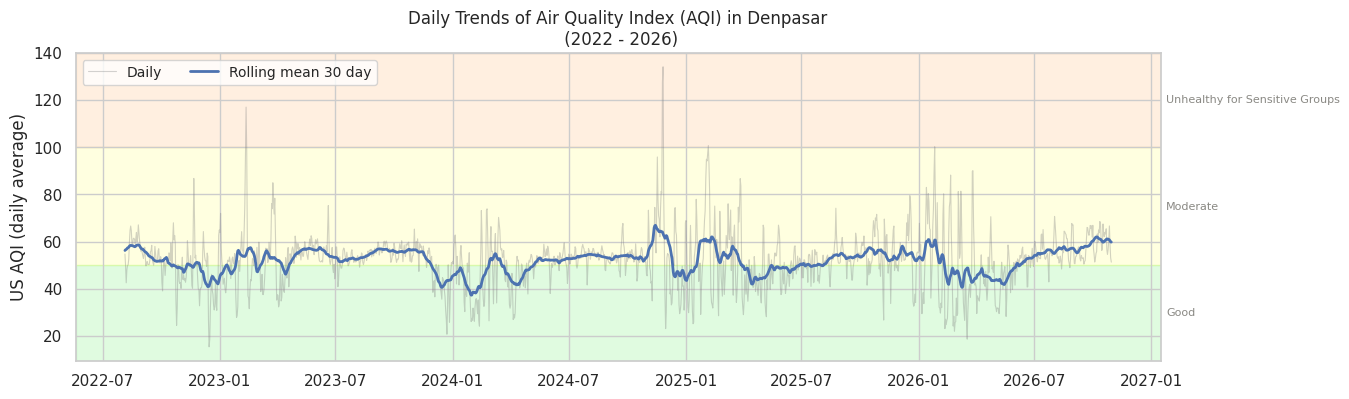

In [24]:
# ===== Daily AQI trend (2022–2026) =====
# Date-indexed daily frame shared by the EDA and Data Preparation sections
df_clean = df_denpasar.set_index("date")
# EDA frame: adds the next-day target used by the correlation and scatter analyses
df_plot = df_clean.assign(**{TARGET_NEXT_DAY: df_clean[TARGET].shift(-1)})

# Line chart with a rolling mean and AQI category bands
ax = plot_line(df_plot[TARGET], title="Daily Trends of Air Quality Index (AQI) in Denpasar\n (2022 - 2026)",
               ylabel="US AQI (daily average)", rolling_window=TREND_ROLLING_WINDOW)
shade_aqi_categories(ax)
plt.show()

**Insight: daily AQI trend.** Between August 2022 and October 2026, Denpasar's daily US AQI stayed
mostly in the *Moderate* band. The 30-day rolling mean moved between roughly 38 and 67 around an
overall mean of 52. Unhealthy days are rare and short-lived. Daily values crossed AQI 100 only in
brief spikes: February 2023 (≈117), November 2024 (≈134, the series maximum), and around January 2025
and January 2026 (≈100). The cleanest periods were January–April 2024 and March–May 2026, when the
rolling mean dropped into the *Good* band (≈38–45).

The practical message for stakeholders is that Denpasar's air is not chronically unhealthy. Its
risk lies in a persistently moderate baseline punctuated by short spikes, which are easy to miss
without daily monitoring.

In [25]:
# ===== Air quality baseline KPIs (Goal 1) =====
def season_labels(index: pd.DatetimeIndex) -> np.ndarray:
    """Label each date as "Wet" (November–March) or "Dry" (April–October)."""
    return np.where(index.month.isin(WET_SEASON_MONTHS), "Wet", "Dry")


daily_aqi = df_clean[TARGET]
annual_kpis = daily_aqi.groupby(daily_aqi.index.year).agg(
    days="size",
    mean_aqi="mean",
    pct_days_above_100=lambda s: (s > 100).mean() * 100,
)
annual_kpis["yoy_change_pct"] = annual_kpis["mean_aqi"].pct_change() * 100
seasonal_mean = daily_aqi.groupby(season_labels(daily_aqi.index)).mean()

print(annual_kpis.round(2))
print(f"\nDays above AQI 100: {(daily_aqi > 100).sum()} of {len(daily_aqi)} "
      f"({(daily_aqi > 100).mean():.1%})")
print(f"Mean AQI by season: dry {seasonal_mean['Dry']:.1f} | wet {seasonal_mean['Wet']:.1f} "
      f"(difference {seasonal_mean['Dry'] - seasonal_mean['Wet']:+.1f})")

      days  mean_aqi  pct_days_above_100  yoy_change_pct
date                                                    
2022   149     50.63                0.00             NaN
2023   365     52.85                0.27            4.39
2024   366     51.18                0.55           -3.15
2025   365     52.21                0.27            2.00
2026   303     52.27                0.33            0.12

Days above AQI 100: 5 of 1548 (0.3%)
Mean AQI by season: dry 52.4 | wet 51.3 (difference +1.0)


**Insight: baseline KPIs.**

* **A remarkably stable level.** Annual mean AQI moved within a narrow band of 50.6 to 52.9.
  Among the complete years, it ranged from 51.2 (2024) to 52.9 (2023). The years 2022
  (August–December) and 2026 (January–October) are partial, so their figures are indicative only.
* **No trend in either direction.** The mean AQI changed by −3.2% in 2024 and +2.0% in 2025, and by
  +0.1% in the first ten months of 2026. Denpasar's air is neither clearly improving nor
  deteriorating.
* **Unhealthy days are rare, and they cluster.** Only 5 of 1,548 days (0.3%) exceeded AQI 100: one
  each in 2023, 2025, and 2026, and two in 2024. According to the daily trend chart, all of them fall
  in the November–February window (February 2023, November 2024, January 2025, and January 2026).
* **Seasons barely differ on average.** The mean AQI was 52.4 in the dry season and 51.3 in the wet
  season, a difference of only +1.0 point.

The risk therefore sits less in a "bad season" than in **short, sharp episodes**, which a daily
forecast is designed to catch.

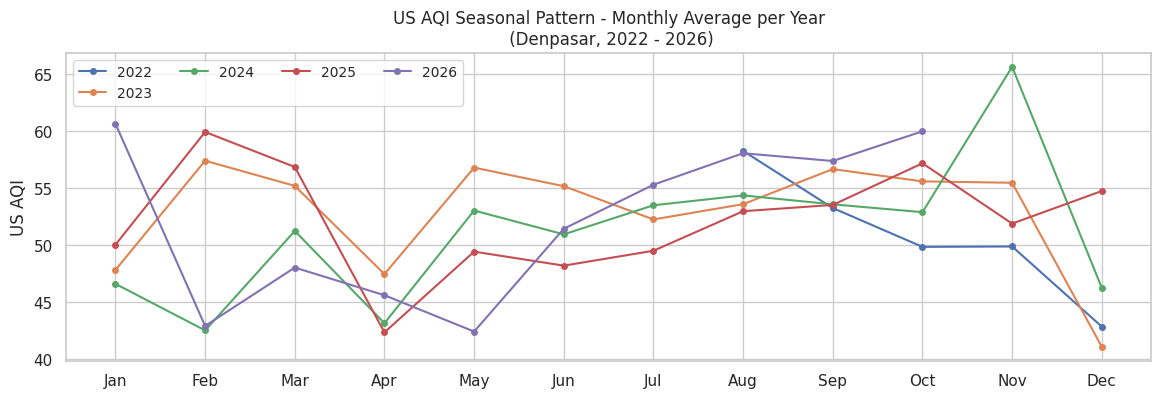

In [26]:
# ===== Seasonal pattern: monthly mean AQI per year =====
seasonal = df_plot.pivot_table(
    index=df_plot.index.month, columns=df_plot.index.year,
    values=TARGET, aggfunc="mean"
)
ax = plot_line(
    seasonal,
    title="US AQI Seasonal Pattern - Monthly Average per Year\n (Denpasar, 2022 - 2026)",
    ylabel="US AQI"
)
ax.set_xticks(range(1, 13), MONTH_LABELS)
plt.show()

**Insight: monthly profile per year.** Monthly mean AQI stayed between ≈41 and ≈66 in every year.
The spread between years within the same month, up to ≈17 points in February, is larger than any
recurring seasonal swing, so the calendar alone is a weak predictor. Two regularities still stand
out:

* **August–October** sits at roughly 50–60 in every year, in line with the late dry season.
* **April** is among the two lowest months in 2023, 2024, and 2025.

The highest monthly mean, **November 2024 (≈66)**, is an outlier rather than a recurring pattern. It
coincides with the CAMS 49r1 model upgrade on 12 November 2024, so part of this jump may reflect a
change in the data-generating model rather than in the air itself.

#### 4.5.3 Weather and Pollutant Trends

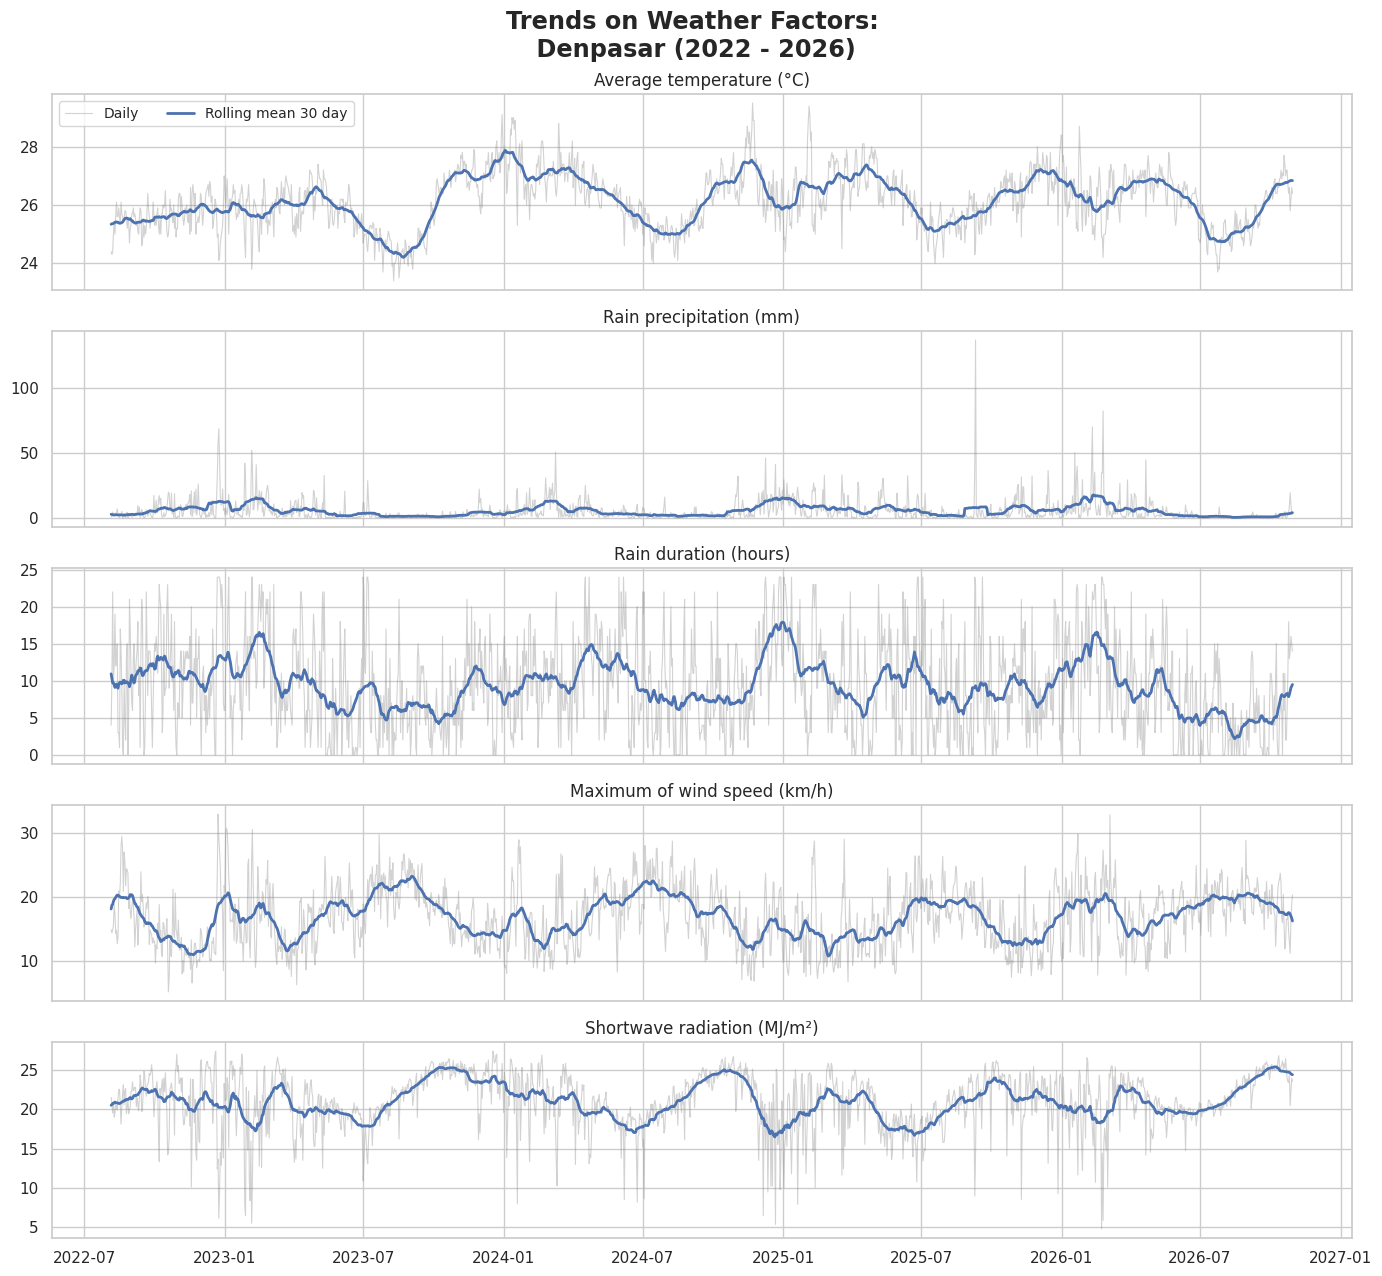

In [27]:
# ===== Weather variable trends =====
plot_small_multiples(
    df_plot,
    WEATHER_FEATURES,
    suptitle="Trends on Weather Factors:\n Denpasar (2022 - 2026)"
)
plt.show()

**Insight: weather trends.** The weather variables follow Bali's monsoon cycle clearly and
repeatedly:

* **Temperature** (30-day mean 24–28 °C) is lowest in July–September, during the cool, dry east
  monsoon, and highest in November–January. The 2023 dry season was the coolest (≈24.3 °C).
* **Rainfall** is concentrated in December–March and drops to almost zero in July–September. A
  single extreme day of 137 mm occurred in the second half of 2025.
* **Rain duration** peaks at 16–18 hours per day (30-day mean) in February 2023, December 2024 –
  January 2025, and February 2026, and falls to about 5 hours in June–September. The weaker peak in
  early 2024 is consistent with drier conditions after the 2023 El Niño.
* **Maximum wind speed** (30-day mean 11–23 km/h) is strongest in July–September (east monsoon),
  with secondary peaks around January (west monsoon). It is weakest during the monsoon transitions
  in April–May and October–November.
* **Shortwave radiation** (17–25 MJ/m²) peaks in October–November, when skies are clear and the
  sun is close to the zenith over Bali, and dips in January (cloud cover) and June–July (lower sun
  angle). It is relevant as a driver of photochemical ozone formation.

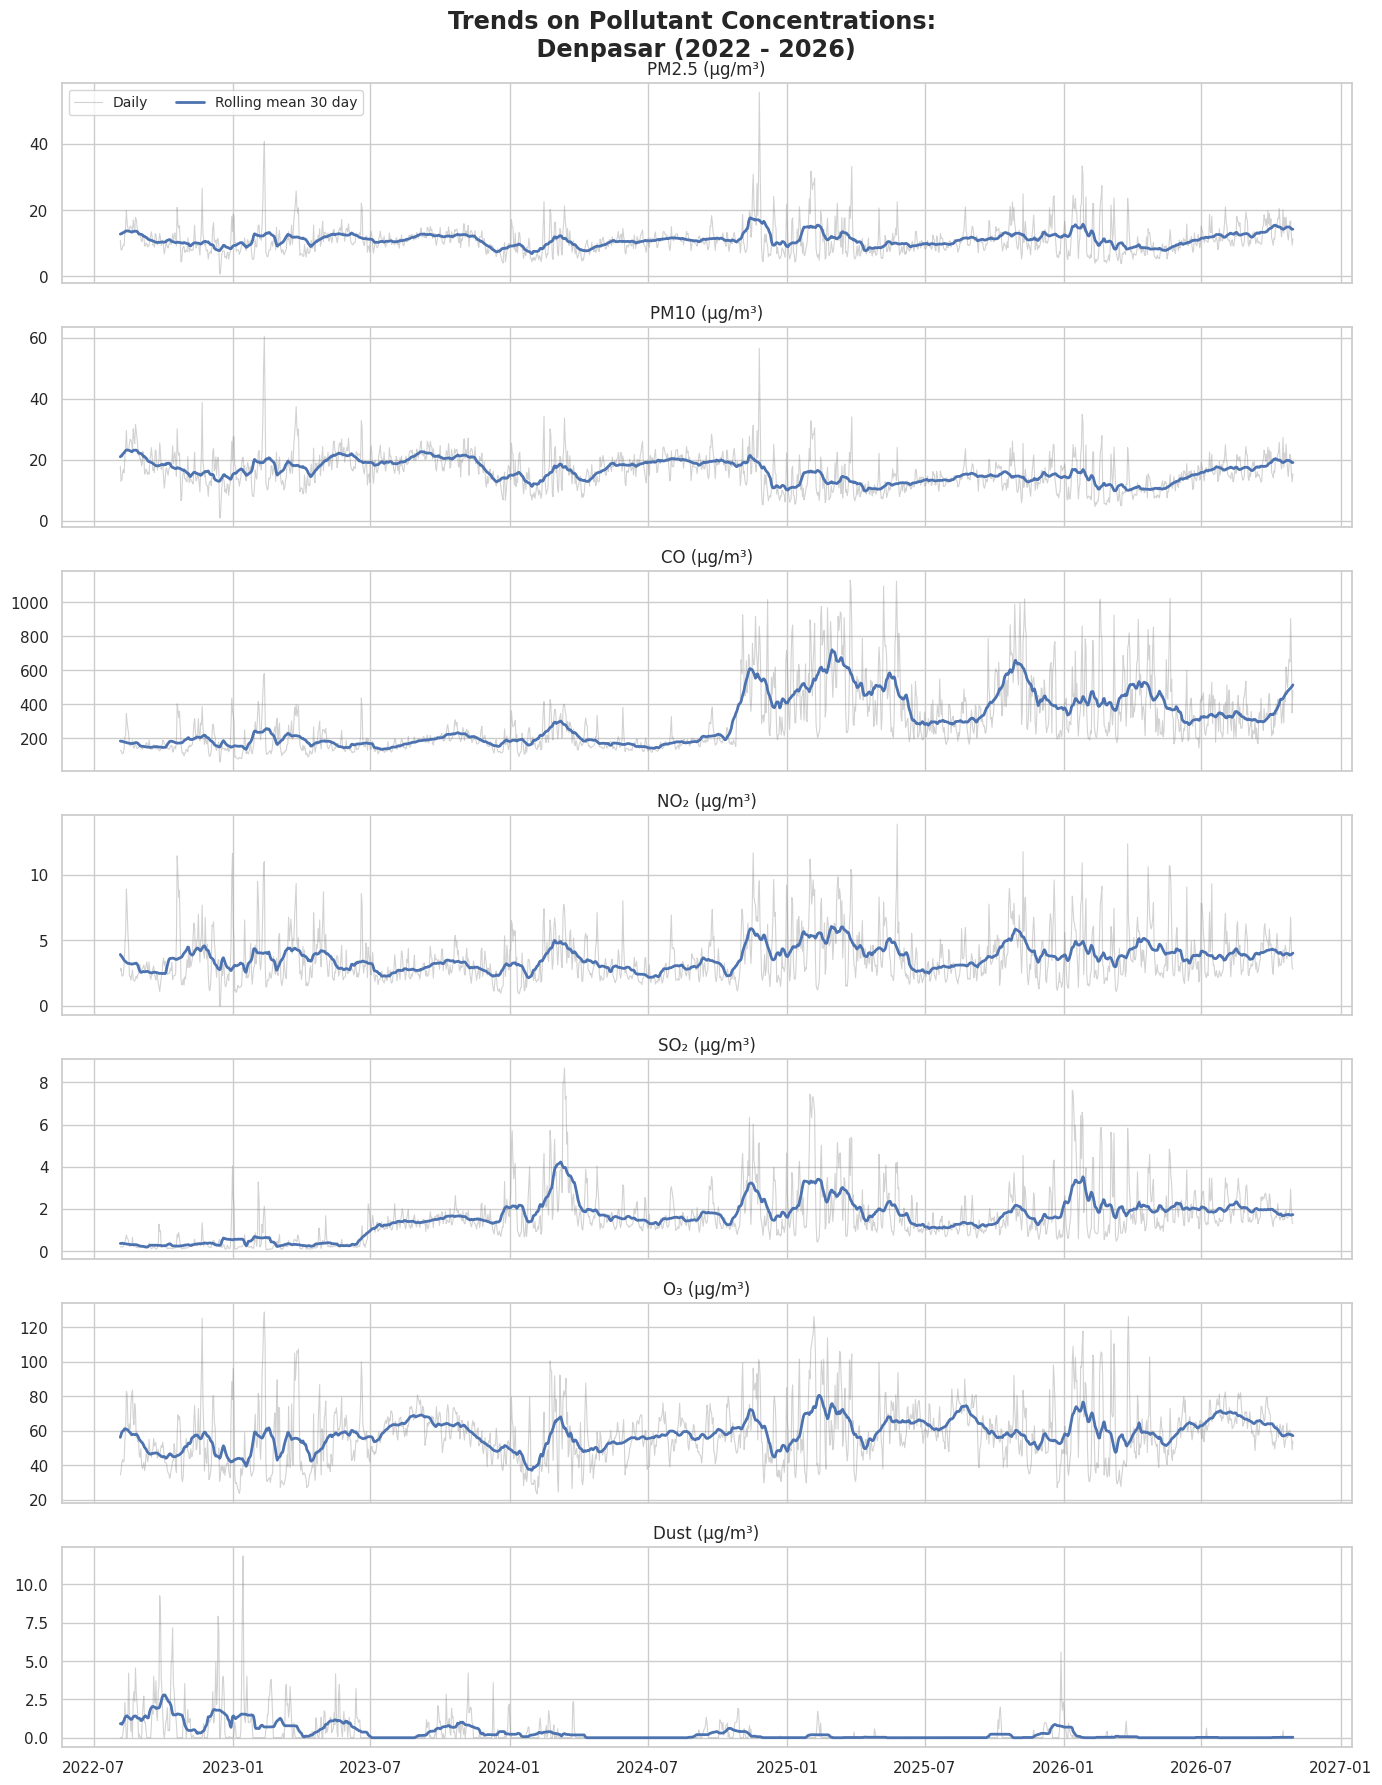

In [28]:
# ===== Pollutant concentration trends =====
plot_small_multiples(
    df_plot,
    POLLUTANT_FEATURES,
    suptitle="Trends on Pollutant Concentrations:\n Denpasar (2022 - 2026)"
)
plt.show()

**Insight: pollutant trends.** The pollutant series reveal both real episodes and data-regime
shifts:

* **PM2.5** (30-day mean 8–18 µg/m³) stays above the WHO annual guideline (5 µg/m³) throughout the
  period. Its largest episode, in November–December 2024, reached a daily value of ≈55 µg/m³.
* **CO** shows a step change from ≈200 to 400–700 µg/m³ in **November 2024**, exactly when CAMS 49r1
  went live, and has remained higher and more volatile since. **NO₂** rises at the same time
  (≈3 → 4–6 µg/m³), and **PM10** shifts down (≈20 → 10–15 µg/m³) before gradually recovering to ≈19
  in 2026. Abrupt, simultaneous shifts like these are typical of a model change, not of emission
  trends.
* **SO₂** steps up in mid-2023 (≈0.3 → 1.5 µg/m³) and has peaked in the first quarter of every year
  since 2024. The 2023 step does not match a recorded CAMS upgrade and should be treated as an open
  data-quality question.
* **O₃** fluctuates between 40 and 80 µg/m³, with its highest levels in early 2025 and early 2026.
* **Dust** has been close to zero since mid-2023 and carries almost no information.

For modelling, the November 2024 shift is encoded as a regime flag (`post_cams_49r1`), and dust is
excluded from the model inputs.

#### 4.5.4 Association between Weather, Pollutants, and AQI

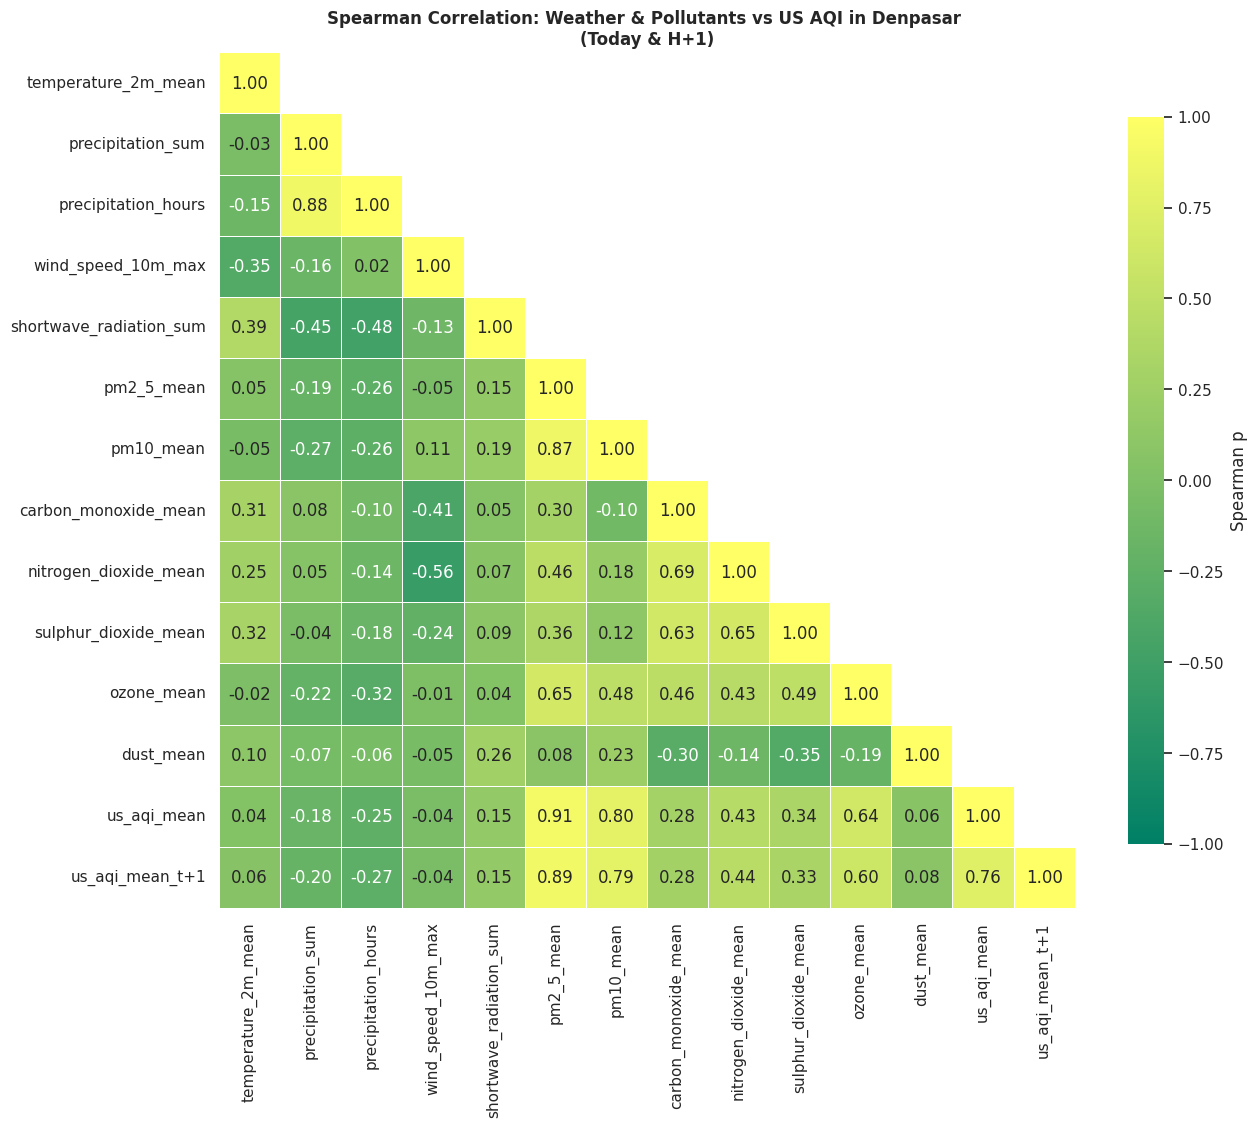

In [29]:
# ===== Spearman correlation: weather and pollutants vs AQI (day t and t+1) =====
corr = plot_corr_heatmap(
    df_plot,
    [*WEATHER_FEATURES, *POLLUTANT_FEATURES, TARGET, TARGET_NEXT_DAY],
    title="Spearman Correlation: Weather & Pollutants vs US AQI in Denpasar \n(Today & H+1)"
)
plt.show()

**Insight: Spearman correlation.**

* **Particulates dominate the index.** PM2.5 has the strongest association with AQI
  (ρ = 0.91 same day, 0.89 next day), followed by PM10 (0.80 / 0.79) and O₃ (0.64 / 0.60). NO₂
  (0.43 / 0.44), SO₂ (0.34 / 0.33), and CO (0.28 / 0.28) are moderate to weak. Because the US AQI is
  calculated from pollutant concentrations, and PM2.5 usually sets the index, these correlations are
  partly definitional. They confirm PM2.5 as the pollutant to prioritise, but they do not establish a
  cause.
* **Weather acts indirectly and weakly.** Rain duration (ρ = −0.25 / −0.27) and precipitation
  (−0.18 / −0.20) are associated with lower AQI, shortwave radiation is weakly positive (0.15), and
  temperature and wind speed are close to zero.
* **Wind dilutes combustion gases.** Wind speed is clearly negatively correlated with NO₂
  (ρ = −0.56) and CO (−0.41), even though its direct link to the AQI is weak.
* **Shared sources.** CO, NO₂, and SO₂ are mutually correlated (ρ = 0.63–0.69), which is consistent
  with common combustion sources. PM2.5 and PM10 are also strongly linked (ρ = 0.87).
* **Persistence.** Today's AQI correlates with tomorrow's at ρ = 0.76, which motivates lagged AQI
  features.

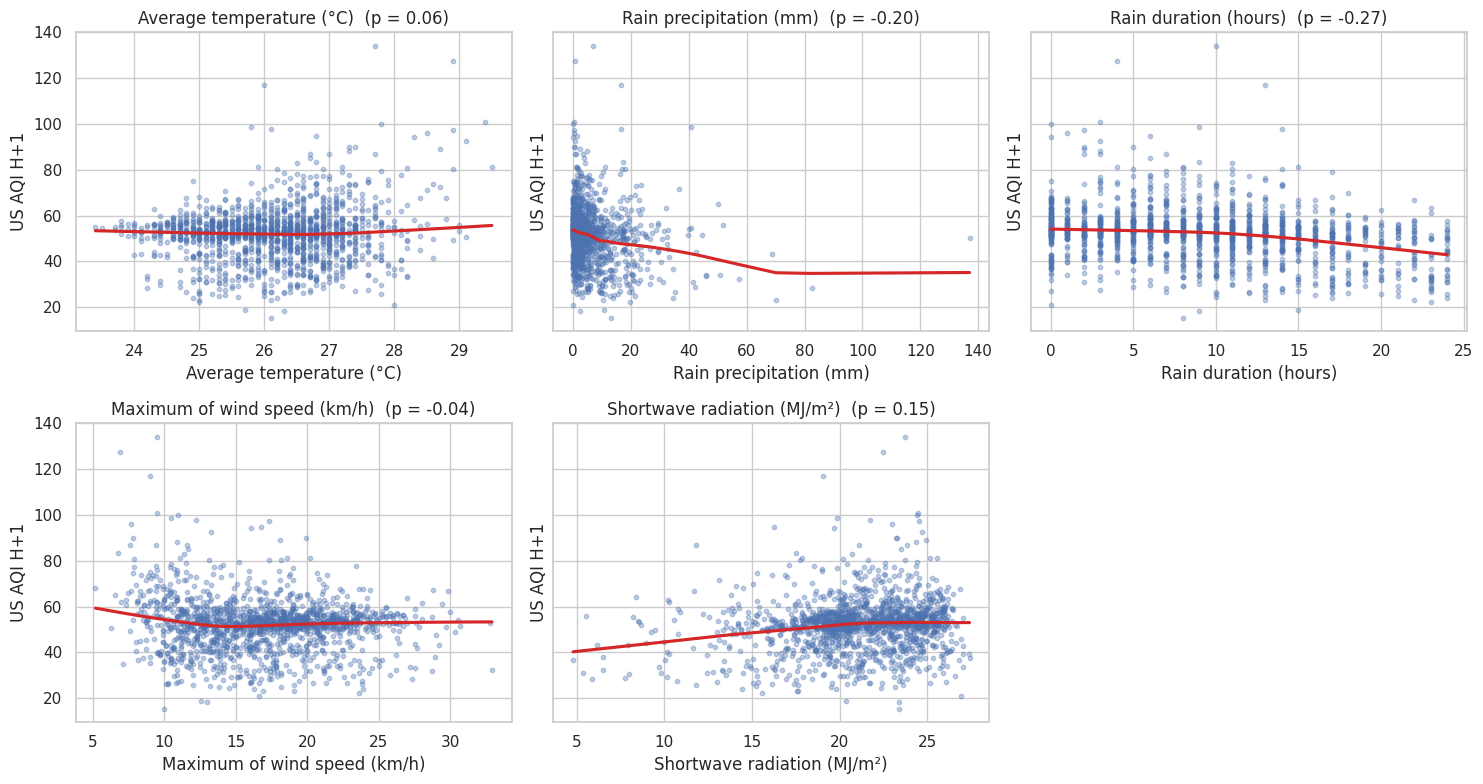

/usr/local/lib/python3.13/dist-packages/statsmodels/nonparametric/smoothers_lowess.py:237: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(


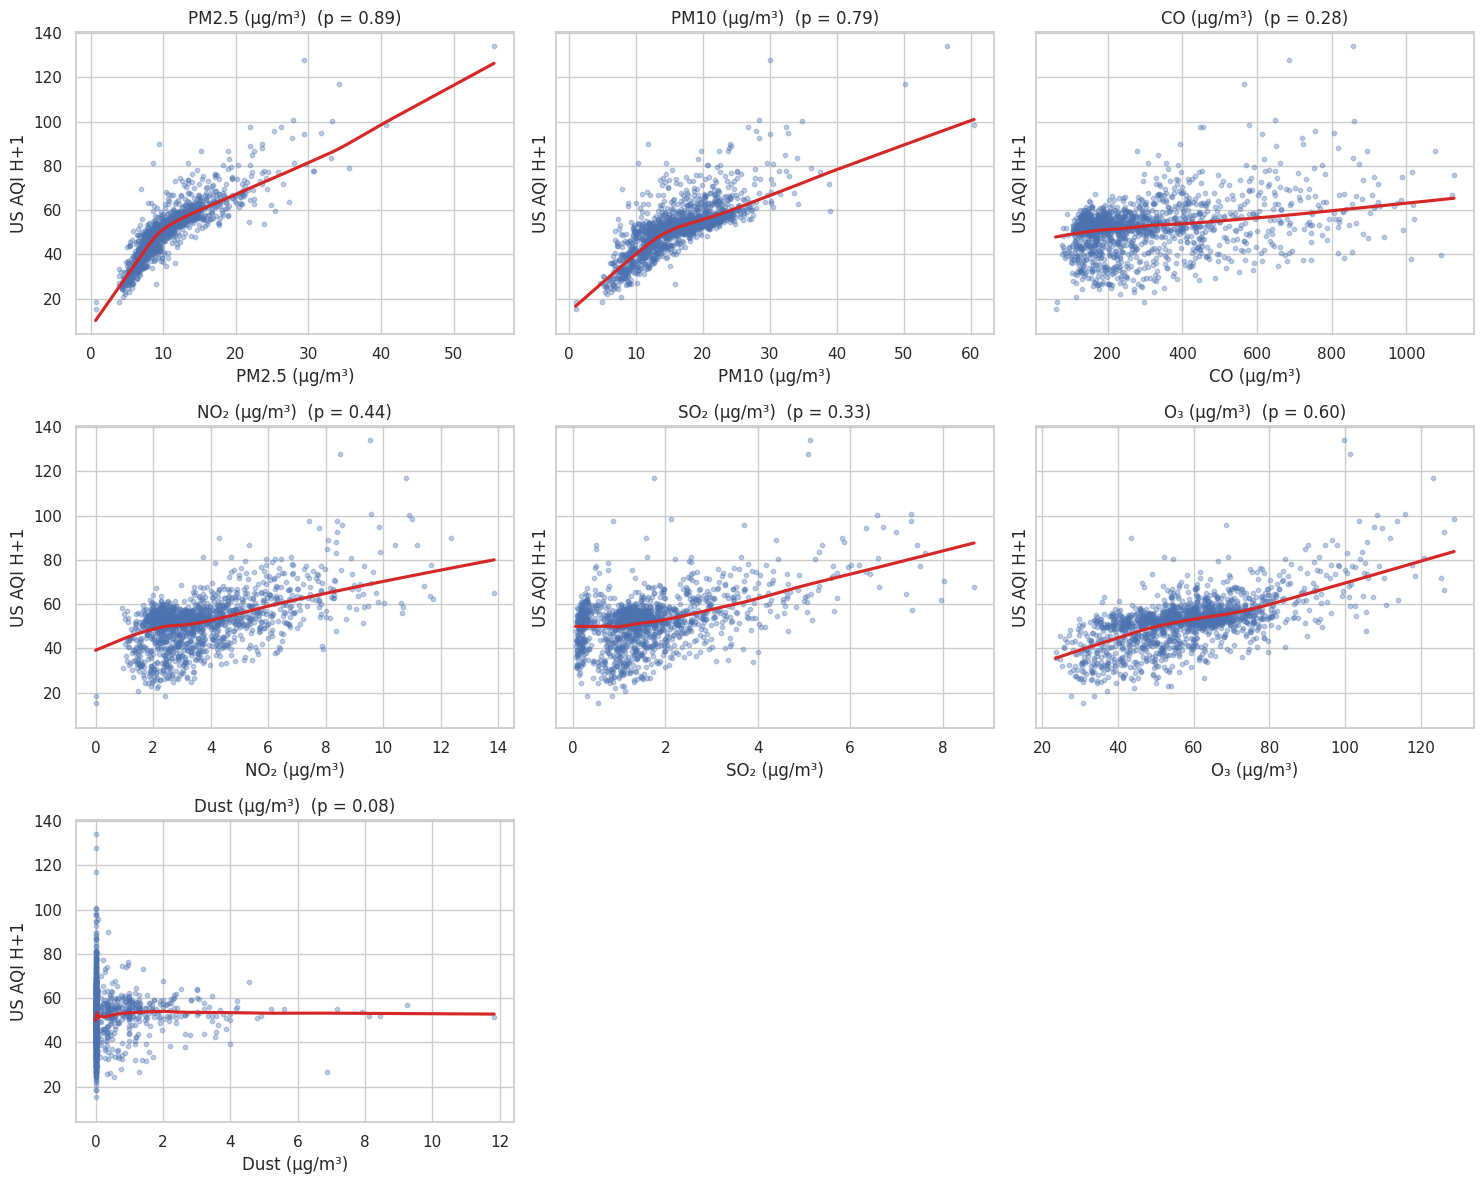

In [30]:
# ===== Scatter plots: features vs next-day AQI =====
for feature_group in (WEATHER_FEATURES, POLLUTANT_FEATURES):
    plot_scatter_grid(
        df_plot,
        feature_group,
        target=TARGET_NEXT_DAY,
        target_label="US AQI H+1"
    )
    plt.show()

**Insight: non-linear relationships (LOWESS curves against next-day AQI).**

* **Rainfall has diminishing returns.** Next-day AQI falls from ≈54 on dry days to ≈35 at about
  70 mm of rain and then flattens. Rain duration lowers AQI gradually once it exceeds about 10 hours.
* **Wind helps only up to a point.** AQI declines from ≈60 at 5 km/h to ≈52 at 15 km/h and is flat
  beyond that, so the dilution effect saturates.
* **Radiation is a dry-weather proxy.** AQI rises from ≈40 at 5 MJ/m² to ≈53 at 20 MJ/m² and then
  levels off, in line with clear, dry days and ozone formation.
* **Temperature has no visible relationship** with next-day AQI.
* **PM2.5 shows a clear knee.** The slope is much steeper below ≈10 µg/m³ than above it. This
  matches the piecewise-linear EPA formula, whose breakpoint between *Good* and *Moderate* lies at
  9.0–12.0 µg/m³ depending on the breakpoint revision. PM10, O₃, and NO₂ rise monotonically, while
  CO and SO₂ are diffuse, and dust is flat.

These threshold-like, saturating patterns favour tree-based models, which capture such
non-linearities without manual transformations.

#### 4.5.5 Temporal Dependence and Seasonality

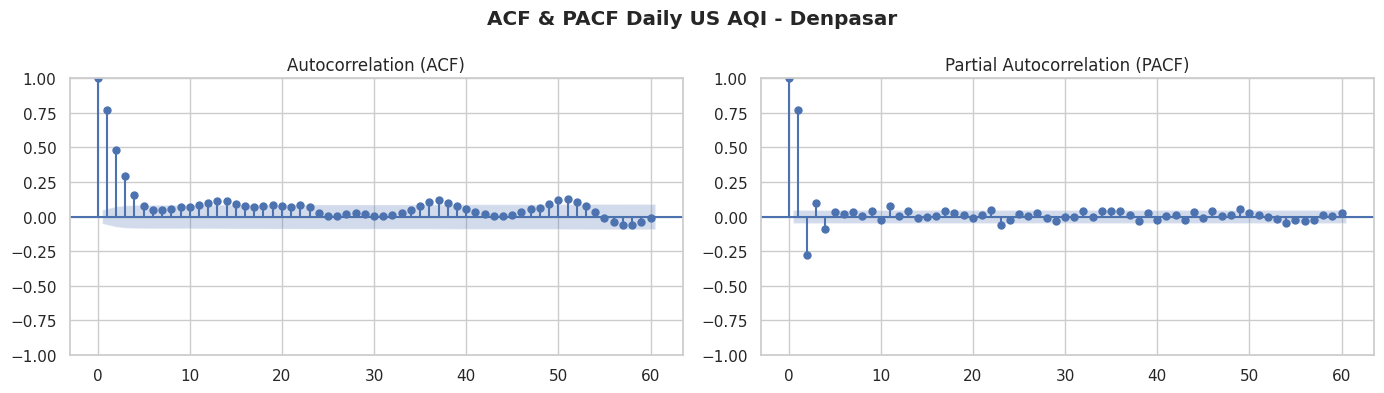

In [31]:
# ===== ACF and PACF analysis for lag feature selection =====
plot_acf_pacf(
    df_plot[TARGET],
    title="ACF & PACF Daily US AQI - Denpasar",
    lags=60
)
plt.show()

**Insight: ACF and PACF.**

* **Short memory.** The autocorrelation is 0.77 at lag 1, 0.48 at lag 2, 0.30 at lag 3, and 0.16 at
  lag 4. Beyond that it stays small (≈0.05–0.12) and shows no 7-day pattern.
* **AR(2)-like structure.** The partial autocorrelation is 0.77 at lag 1 and −0.27 at lag 2, and is
  small or insignificant afterwards.

This is why the model uses AQI lags at t−1 and t−2, with 7- and 30-day rolling statistics for the
longer context, instead of long individual lags.

In [32]:
# ===== Weekly effect, seasonal strength, and annual Fourier seasonality (OLS) =====
def fourier_terms(index: pd.DatetimeIndex, n_harmonics: int) -> dict[str, np.ndarray]:
    """Return sin/cos day-of-year terms for the first ``n_harmonics`` annual harmonics.

    Shared by the seasonal analysis below and by ``build_features`` in Data Preparation.
    """
    angle = 2 * np.pi * index.dayofyear.to_numpy() / DAYS_PER_YEAR
    return {
        f"{func.__name__}_doy_{k}": func(k * angle)
        for k in range(1, n_harmonics + 1)
        for func in (np.sin, np.cos)
    }


def test_weekday_effect(series: pd.Series) -> pd.Series:
    """Return the median AQI per weekday and print a Kruskal–Wallis test for a weekly effect."""
    clean = series.dropna()
    by_day = clean.groupby(clean.index.dayofweek)
    p_value = kruskal(*(values for _, values in by_day)).pvalue
    print(f"Kruskal–Wallis days per week: p = {p_value:.3f}\n")
    return by_day.median().rename(index=dict(enumerate(calendar.day_abbr))).round(1)


def seasonal_strength(components: pd.DataFrame) -> pd.Series:
    """Share of variance explained by the annual seasonal component (daily and monthly)."""
    monthly = components.resample("MS").mean()
    return pd.Series({
        scale: 1 - frame["deseasonalized"].var() / frame["observed"].var()
        for scale, frame in {"daily": components, "monthly": monthly}.items()
    }).round(3)


def fit_annual_harmonics(series: pd.Series, *, n_harmonics: int = N_HARMONICS) -> pd.DataFrame:
    """Estimate the annual seasonal component with a Fourier-term OLS regression.

    Unlike STL/MSTL, this remains stable when the series covers only a few annual
    cycles.
    """
    observed = series.dropna()
    design = np.column_stack(
        [np.ones(len(observed)), *fourier_terms(observed.index, n_harmonics).values()]
    )
    coef, *_ = np.linalg.lstsq(design, observed.to_numpy(), rcond=None)
    seasonal = pd.Series(design[:, 1:] @ coef[1:], index=observed.index)
    return pd.DataFrame({
        "observed": observed,
        "seasonal_annual": seasonal,
        "deseasonalized": observed - seasonal,
    })


def compare_harmonics(series: pd.Series, *, max_harmonics: int = 4) -> pd.DataFrame:
    """Compare the number of harmonics by AIC (OLS with Gaussian errors)."""
    rows = []
    for k in range(1, max_harmonics + 1):
        resid = fit_annual_harmonics(series, n_harmonics=k)["deseasonalized"]
        resid = resid - resid.mean()
        n, n_params = len(resid), 1 + 2 * k
        rows.append({"n_harmonics": k, "aic": n * np.log((resid ** 2).sum() / n) + 2 * n_params})
    return pd.DataFrame(rows).set_index("n_harmonics").round(1)


# Weekly (day-of-week) effect
print(f"Weekday Effects: \n{test_weekday_effect(df_plot[TARGET])}")

# Seasonal strength and harmonic selection
print(f"\nSeasonal Strength: \n{seasonal_strength(fit_annual_harmonics(df_plot[TARGET]))}")
print(f"\nHarmonics Comparison: \n{compare_harmonics(df_plot[TARGET])}")
components = fit_annual_harmonics(df_plot[TARGET])
pre_upgrade = fit_annual_harmonics(df_plot.loc[:CAMS_UPGRADES["post_cams_50r1"], TARGET].iloc[:-1])
print("\nPeak month without post-upgrade data:",
      pre_upgrade["seasonal_annual"].groupby(pre_upgrade.index.month).mean().idxmax())

Kruskal–Wallis days per week: p = 0.980

Weekday Effects: 
date
Mon    52.9
Tue    52.8
Wed    52.1
Thu    52.6
Fri    53.2
Sat    52.8
Sun    52.0
Name: us_aqi_mean, dtype: float64

Seasonal Strength: 
daily      0.044
monthly    0.198
dtype: float64

Harmonics Comparison: 
                aic
n_harmonics        
1            7505.6
2            7504.5
3            7490.9
4            7481.8

Peak month without post-upgrade data: 9


**Insight: weekly effect, seasonal strength, and harmonic selection.**

* **No weekly cycle.** The Kruskal–Wallis test gives p = 0.980. Median AQI ranges only from 52.0
  (Sunday) to 53.2 (Friday), a difference of 1.2 points, so day-of-week features are not needed.
* **Seasonality matters for planning, not for day-to-day changes.** The annual seasonal component
  explains 4.4% of the daily variance but 19.8% of the variance of monthly means.
* **Harmonic selection.** The AIC keeps improving as harmonics are added (7505.6 → 7504.5 → 7490.9 →
  7481.8 for 1–4 harmonics). Two harmonics (`N_HARMONICS = 2`) are retained as a smooth,
  parsimonious calendar signal, and three or four harmonics remain a candidate for future tuning.
* **Robust peak month.** When the post-upgrade data (from 12 May 2026) are excluded, the seasonal
  peak still falls in September, so the peak is not an artefact of the CAMS 50r1 upgrade.

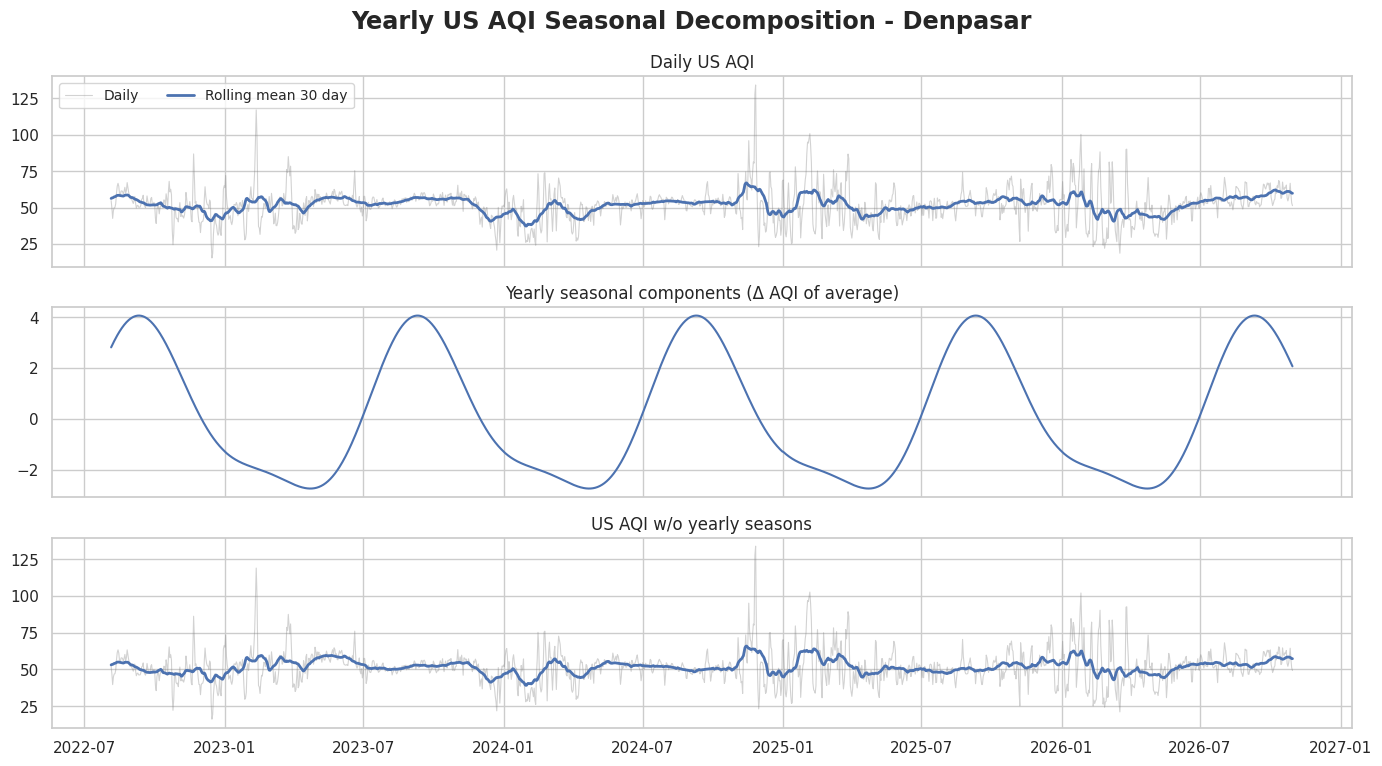

In [33]:
plot_small_multiples(
    components,
    {"observed": "Daily US AQI",
     "seasonal_annual": "Yearly seasonal components (Δ AQI of average)",
     "deseasonalized": "US AQI w/o yearly seasons"},
    suptitle="Yearly US AQI Seasonal Decomposition - Denpasar",
    smooth_features={"seasonal_annual"},
)
plt.show()

**Insight: annual seasonal decomposition.**

* **Asymmetric shape.** The seasonal component peaks at about +4 AQI in mid-September and bottoms out
  at about −2.7 in late April. AQI declines slowly from October to April (≈7 months) and rises quickly
  from May to September (≈4–5 months).
* **Small amplitude.** The peak-to-trough range is about 6.7 AQI points, roughly 13% of the mean
  of 52.
* **Episodes are not seasonal.** The deseasonalised series looks almost identical to the original.
  The episodes of February 2023, November–December 2024, and January–February 2026 remain intact, so
  most day-to-day variation comes from non-seasonal factors.
* **A recent upward drift.** From July to October 2026, the deseasonalised 30-day mean rises into
  the high 50s, its highest sustained level in the period. This follows the CAMS 50r1 upgrade of May
  2026 and deserves monitoring.

#### 4.5.6 Stationarity

In [34]:
# ===== Stationarity tests: ADF, KPSS, and Zivot–Andrews =====
# Maps (ADF rejects H0, KPSS rejects H0) to the combined verdict
STATIONARITY_VERDICTS: dict[tuple[bool, bool], str] = {
    (True, False): "Stationary",
    (False, True): "Non-stationary (unit root)",
    (False, False): "Trend-stationary: remove trend, then retest again",
    (True, True): "Inconsistent: might be structural break (check Zivot-Andrews) or difference-stationary",
}


@dataclass(frozen=True)
class TestResult:
    """Outcome of one stationarity test, normalized across ADF, KPSS, and Zivot–Andrews."""

    test: str
    null_hypothesis: str
    statistic: float
    pvalue: float
    critical_5pct: float
    lags: int
    reject_null: bool
    pvalue_is_bound: bool = False
    break_date: pd.Timestamp | None = None


def _validate(series: pd.Series) -> pd.Series:
    """Reject series containing NaN values and cast to float."""
    if series.isna().any():
        raise ValueError("Series contains NaN; please handle any missing values found before testing.")
    return series.astype(float)


def run_adf(series: pd.Series, *, regression: str = "c", alpha: float = ALPHA) -> TestResult:
    """Run the augmented Dickey–Fuller test (H0: the series has a unit root)."""
    res = adfuller(_validate(series), regression=regression, autolag="AIC", result_object=True)
    return TestResult("ADF", "There is unit root (non-stationary) exist", res.statistic, res.pvalue,
                      res.critical_values["5%"], res.lags, res.pvalue <= alpha)


def run_kpss(series: pd.Series, *, regression: str = "c", alpha: float = ALPHA) -> TestResult:
    """Run the KPSS test (H0: the series is stationary).

    statsmodels clips the p-value to its lookup-table range and emits an
    ``InterpolationWarning``; the warning is captured so the result can be
    flagged as a bound rather than an exact value.
    """
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InterpolationWarning)
        res = kpss(_validate(series), regression=regression, nlags="auto", result_object=True)
    is_bound = any(issubclass(w.category, InterpolationWarning) for w in caught)
    return TestResult("KPSS", "Stationary", res.statistic, res.pvalue,
                      res.critical_values["5%"], res.lags, res.pvalue <= alpha, is_bound)


def run_zivot_andrews(
    series: pd.Series, *, regression: str = "c", alpha: float = ALPHA, trim: float = 0.15
) -> TestResult:
    """Run the Zivot–Andrews unit-root test with one endogenously selected break.

    ``trim`` is the fraction of observations excluded at each end of the sample
    when searching for the break date.
    """
    clean = _validate(series)
    stat, pvalue, crit, lags, break_idx = zivot_andrews(clean, trim=trim, regression=regression)
    return TestResult("Zivot-Andrews", "There is unit root with one structural break found", stat, pvalue,
                      crit["5%"], lags, pvalue <= alpha, break_date=clean.index[break_idx])


def format_pvalue(result: TestResult) -> str:
    """Format a p-value, marking KPSS values clipped at the table boundary."""
    if result.pvalue_is_bound:
        return f"{'<' if result.reject_null else '>'} {result.pvalue:.2f} (table boundary)"
    return "<0.001" if result.pvalue < 0.001 else f"{result.pvalue:.3f}"


def stationarity_report(
    series: pd.Series, *, regression: str = "c", alpha: float = ALPHA, za_trim: float = 0.15
) -> pd.DataFrame:
    """Run ADF, KPSS, and Zivot–Andrews and return a summary table.

    The combined ADF + KPSS verdict (see ``STATIONARITY_VERDICTS``) is printed.
    """
    results = [run_adf(series, regression=regression, alpha=alpha),
               run_kpss(series, regression=regression, alpha=alpha),
               run_zivot_andrews(series, regression=regression, alpha=alpha, trim=za_trim)]
    verdict = STATIONARITY_VERDICTS[(results[0].reject_null, results[1].reject_null)]
    print(f"Conclusion of ADF + KPSS (regression='{regression}', α = {alpha}): {verdict}")
    return pd.DataFrame([
        {"Test": r.test, "H0": r.null_hypothesis, "Statistic": round(r.statistic, 3),
         "Critical value of 5%": round(r.critical_5pct, 3), "p-value": format_pvalue(r),
         "Lag": r.lags, "Reject H0": r.reject_null,
         "Break date": r.break_date.date() if r.break_date is not None else "–"}
        for r in results
    ]).set_index("Test")


# Run all three tests on the daily AQI series
stationarity_report(df_plot[TARGET], za_trim=ZA_TRIM)

Conclusion of ADF + KPSS (regression='c', α = 0.05): Stationary


,H0,Statistic,Critical value of 5%,p-value,Lag,Reject H0,Break date
Test,,,,,,,
ADF,There is unit root (non-stationary) exist,-9.028,-2.863,<0.001,10,True,–
KPSS,Stationary,0.110,0.463,> 0.10 (table boundary),18,False,–
Zivot-Andrews,There is unit root with one structural break f...,-9.359,-4.811,<0.001,10,True,2026-06-30


**Insight: ADF, KPSS, and Zivot–Andrews tests.**

* **Stationary in levels.** ADF rejects a unit root (statistic −9.028 vs. a 5% critical value of
  −2.863, p < 0.001), and KPSS does not reject stationarity (0.110 vs. 0.463, p > 0.10). The two
  tests agree that the AQI fluctuates around a constant mean, so no differencing is needed.
* **Robust to a structural break.** Zivot–Andrews also rejects a unit root while allowing for one
  break (−9.359 vs. −4.811). The most likely break date, **30 June 2026**, falls inside the test
  period, about seven weeks after the CAMS 50r1 upgrade.

The test period therefore contains a regime shift. This makes it a demanding out-of-sample check,
and it is why the exported metrics are grouped by CAMS regime.

#### 4.5.7 EDA Summary

1. **Baseline.** Denpasar's AQI averages 52, at the lower edge of *Moderate*, with short and rare
   spikes above 100. PM2.5 stays above the WHO annual guideline throughout the period.
2. **Drivers.** PM2.5 is the pollutant most closely tied to the AQI. Rainfall and rain duration
   lower the next-day AQI with diminishing returns, and wind mainly dilutes combustion gases.
3. **Dynamics.** The series is stationary with short (AR(2)-like) memory, no weekly cycle, and a
   weak, asymmetric annual cycle that peaks in September.
4. **Data regimes.** CAMS model upgrades (November 2024, May 2026) and an unexplained SO₂ step in
   2023 create level shifts that the model must account for.

### 4.6 From EDA to Data Preparation: Steps to Take

The EDA findings translate into concrete preparation decisions:

| EDA finding | Preparation decision | Section |
|---|---|---|
| AQI memory is short (PACF significant at lags 1–2) | AQI lags t−1 and t−2, plus 7- and 30-day rolling mean, max, and std | 5.1 |
| Weak, asymmetric annual cycle (4.4% of daily, 19.8% of monthly variance) | Two annual Fourier harmonics of the day of year | 5.1 |
| No weekday effect (Kruskal–Wallis p = 0.98) | No day-of-week features | 5.1 |
| Rain lowers next-day AQI with diminishing returns | Same-day rainfall plus 3- and 7-day rainfall sums | 5.1 |
| Series is stationary (ADF and KPSS agree) | Model AQI levels directly, without differencing | 5.1 |
| Level shifts at the CAMS 49r1 upgrade | `post_cams_49r1` regime flag; the 50r1 flag is kept for evaluation only | 5.1, 7 |
| Dust is close to zero since 2023 | Exclude `dust_mean` from model inputs | 5.1 |
| Strong correlations between some inputs | Redundancy filter on the train split (\|ρ\| > 0.95) | 5.3 |
| Structural break inside the test period | Strictly chronological split with an embargo; regime-aware metrics | 5.2, 8.3 |

The preparation pipeline runs in four phases. Each phase only uses operations that cannot leak
information from the future into the past:

**Phase A: before the split (causal or stateless operations only)**

1. Validate that the daily series is continuous and that the imputation flag exists.
2. Export the clean daily dataset for the dashboard. This branch is independent of the model
   pipeline.
3. Drop identifier, constant, and domain-redundant attributes.
4. Build the targets AQI t+1 … t+7 and flag rows whose targets include imputed values.
5. Build causal features: lags, rolling statistics ending at day t, Fourier terms, and regime flags.
6. Drop the warm-up rows of the 30-day window and the last rows without a complete set of targets.

**Phase B: chronological split**

7. Split into train, validation, and test (65/15/20) by date, with a 6-day embargo between splits.

**Phase C: fitted on the train split only**

8. Remove redundant features using correlations computed on the train split.
9. Probe feature relevance with permutation importance on the validation split.
10. Confirm that no categorical encoding is needed.
11. Export the preprocessing artifacts: ordered feature list, split boundaries, and data version.

**Phase D: model-ready datasets**

12. Build tabular matrices with sample weights (0 for imputed targets) and define 10 walk-forward
    cross-validation folds on train + validation.

## 5. Data Preparation

The section follows the CRISP-DM Data Preparation tasks, organised into four leakage-safe phases:

| CRISP-DM task | Where it happens |
|---|---|
| Select data | 5.1 attribute selection; 5.3 redundancy filter and feature relevance check |
| Clean data | 4.4.2 gap trimming and interpolation; 5.1 forward-fill of short exogenous gaps |
| Construct data | 5.1 features and targets |
| Integrate data | 4.4.1 merge of the three sources |
| Format data | 5.4 tabular matrices and sample weights |
| Generate test design *(a Modeling task)* | 5.2 chronological split; 5.4 walk-forward folds |

### 5.1 Phase A: Before the Split

The feature builders below are causal by construction: every feature for day t uses only data up to
and including day t. Exogenous gaps of up to `MAX_FFILL_DAYS` days are forward-filled, which only
carries past values forward, and the targets are shifted values of the future AQI.

In [35]:
def add_regime_flags(df: pd.DataFrame) -> pd.DataFrame:
    """Add 0/1 flags for days on or after each CAMS model upgrade (expects a DatetimeIndex)."""
    return df.assign(**{
        name: (df.index >= pd.Timestamp(date)).astype("int8")
        for name, date in CAMS_UPGRADES.items()
    })


def add_dashboard_columns(df: pd.DataFrame) -> pd.DataFrame:
    """Add helper columns for the dashboard; all values stay in their original units."""
    month = df.index.month
    return add_regime_flags(df).assign(
        year=df.index.year,
        month=month,
        season=pd.Categorical(season_labels(df.index)),
        aqi_category=pd.cut(df[TARGET], bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True),
    )


def build_targets(df: pd.DataFrame) -> pd.DataFrame:
    """Build AQI targets t+1 ... t+H and flag rows in which any target was imputed."""
    aqi, imputed = df[TARGET], df["is_imputed"].astype(bool)
    steps = range(1, HORIZON + 1)
    targets = pd.DataFrame({col: aqi.shift(-h) for h, col in zip(steps, TARGET_COLS)})
    any_imputed = pd.concat([imputed.shift(-h, fill_value=False) for h in steps], axis=1).any(axis=1)
    return targets.assign(target_is_imputed=any_imputed)


def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Build causal forecasting features: every feature uses data up to day t only."""
    exog = df[POLLUTANT_COLS + WEATHER_COLS].ffill(limit=MAX_FFILL_DAYS)
    aqi, rain = df[TARGET], exog["precipitation_sum"]
    engineered = {
        "aqi_t": aqi,
        **{f"aqi_t-{lag}": aqi.shift(lag) for lag in AQI_LAGS},
        **{f"aqi_roll{w}_{stat}": getattr(aqi.rolling(w, min_periods=w), stat)()
           for w in ROLLING_WINDOWS for stat in ROLLING_STATS},
        **{f"precip_sum_{w}d": rain.rolling(w, min_periods=w).sum() for w in RAIN_SUM_WINDOWS},
        **fourier_terms(df.index, N_HARMONICS),
    }
    return pd.concat(
        [pd.DataFrame(engineered, index=df.index), exog, add_regime_flags(df)[MODEL_REGIME_FLAGS]],
        axis=1,
    )

In [36]:
# ===== Input validation =====
day_gaps = df_clean.index.to_series().diff().dropna()
assert df_clean.index.is_unique and (day_gaps == pd.Timedelta(days=1)).all(), "Daily series is not continuous"
assert df_clean[TARGET].notna().all() and "is_imputed" in df_clean, "Run impute_target_gaps first"
print(f"{len(df_clean)} day: {df_clean.index[0].date()} until {df_clean.index[-1].date()}")

1548 day: 2022-08-05 until 2026-10-30


**Dashboard export.** The clean daily dataset, with helper columns for year, month, season, AQI
category, and CAMS regime, is exported before any modelling step. The dashboard therefore always
shows observed values in their original units.

In [37]:
# ===== Export the clean daily dataset for the Streamlit dashboard =====
df_dashboard = add_dashboard_columns(df_clean)
df_dashboard.to_parquet(DATA_DIR / "dashboard_daily.parquet")
print(f"Export clean dataset for dashboard: {df_dashboard.shape} -> {DATA_DIR / 'dashboard_daily.parquet'}")

Export clean dataset for dashboard: (1548, 39) -> data/processed/dashboard_daily.parquet


In [38]:
# ===== Attribute selection, feature engineering, and targets =====
model_input_cols = {TARGET, "is_imputed", *POLLUTANT_COLS, *WEATHER_COLS}
print("Eliminated attributes:", sorted(set(df_clean.columns) - model_input_cols))

features = build_features(df_clean)
FEATURE_COLS = features.columns.tolist()

df_model = pd.concat([features, build_targets(df_clean)], axis=1).dropna()

assert (df_model.index.to_series().diff().dropna() == pd.Timedelta(days=1)).all(), \
    "Interior NaN rows found (feature gap > MAX_FFILL_DAYS); inspect before continuing"
print(f"df_model: {df_model.shape} | {df_model.index[0].date()} until {df_model.index[-1].date()}")

Eliminated attributes: ['carbon_monoxide_max', 'city', 'dust_max', 'dust_mean', 'et0_fao_evapotranspiration', 'exceeds_who_pm25', 'hours', 'island', 'nitrogen_dioxide_max', 'ozone_max', 'pm2_5_max', 'province', 'sulphur_dioxide_max', 'temperature_2m_max', 'temperature_2m_min', 'us_aqi_max', 'uv_index_max', 'uv_index_mean', 'weather_code', 'wind_gusts_10m_max']
df_model: (1512, 35) | 2022-09-03 until 2026-10-23


**Result.** Twenty attributes are excluded: identifiers, daily maxima that duplicate the means,
dust, the UV index, and weather variables outside the selected set. The modelling table has
**1,512 rows and 35 columns** (27 features, 7 targets, and the imputation flag), covering
3 September 2022 to 23 October 2026. The first 29 days are lost to the 30-day rolling window, and
the last 7 days are dropped because their t+1 … t+7 targets are not yet observed.

### 5.2 Phase B: Chronological Split with Embargo (Test Design)

In CRISP-DM, the test design belongs to the Modeling phase. It is fixed here, before any step that learns from data, so that Phase C can be fitted on the training split only.

Rows are split by date, without shuffling, into train (65%), validation (15%), and test (20%). The
last `EMBARGO = HORIZON − 1 = 6` rows before each boundary are dropped. Without this gap, the 7-day
targets of the final training rows would overlap the next split.

In [39]:
# ===== Chronological train / validation / test split =====
def chronological_split(n_rows: int, ratios: dict[str, float], gap: int = 0) -> dict[str, slice]:
    """Return positional slices for a chronological split (no shuffling).

    The last ``gap`` rows of every split except the final one are dropped because
    their multi-day targets would overlap the next split.
    """
    if abs(sum(ratios.values()) - 1) > 1e-9:
        raise ValueError("Split ratios must sum to 1.")
    edges = [0, *(round(n_rows * cum) for cum in accumulate(ratios.values()))]
    last = len(ratios) - 1
    return {name: slice(start, end - (gap if i < last else 0))
            for i, (name, start, end) in enumerate(zip(ratios, edges[:-1], edges[1:]))}


SPLIT_SLICES = chronological_split(len(df_model), SPLIT_RATIOS, gap=EMBARGO)
split_labels = np.full(len(df_model), "embargo", dtype=object)
for name, positions in SPLIT_SLICES.items():
    split_labels[positions] = name
df_model = df_model.assign(split=pd.Categorical(split_labels, categories=[*SPLIT_RATIOS, "embargo"]))
splits = {name: df_model.iloc[positions] for name, positions in SPLIT_SLICES.items()}
SPLIT_BOUNDS = {name: [part.index[0].date().isoformat(), part.index[-1].date().isoformat()]
                for name, part in splits.items()}

print(pd.DataFrame(SPLIT_BOUNDS, index=["start", "end"]).T.assign(
    rows=[len(part) for part in splits.values()]))

            start         end  rows
train  2022-09-03  2025-05-06   977
val    2025-05-13  2025-12-19   221
test   2025-12-26  2026-10-23   302


**Result.** Train covers 3 September 2022 – 6 May 2025 (977 rows), validation 13 May – 19 December
2025 (221 rows), and test 26 December 2025 – 23 October 2026 (302 rows). The test period includes
the CAMS 50r1 upgrade (12 May 2026) and the structural break detected on 30 June 2026, which makes
it a demanding out-of-sample check.

### 5.3 Phase C: Fitted on the Train Split Only

Every step that learns from data is fitted on the train split only, so the validation and test
splits stay unseen.

In [40]:
# ===== Drop redundant features (correlations computed on train only) =====
def drop_redundant_features(train: pd.DataFrame, candidates: list[str], targets: list[str],
                            threshold: float = CORR_THRESHOLD) -> tuple[list[str], list[str]]:
    """Drop one feature from each highly correlated pair.

    For every pair with |Spearman rho| above ``threshold`` (computed on the train
    split), the feature with the weaker mean absolute correlation to the targets
    t+1 ... t+H is dropped. Returns ``(kept_features, dropped_features)``.
    """
    corr = train[candidates].corr(method="spearman").abs()
    relevance = pd.concat(
        [train[candidates].corrwith(train[t], method="spearman").abs() for t in targets], axis=1
    ).mean(axis=1)
    dropped: set[str] = set()
    for i, first in enumerate(candidates):
        for second in candidates[i + 1:]:
            if {first, second} & dropped or corr.loc[first, second] <= threshold:
                continue
            dropped.add(min(first, second, key=relevance.get))
    return [c for c in candidates if c not in dropped], sorted(dropped)


SELECTED_FEATURES, redundant = drop_redundant_features(splits["train"], FEATURE_COLS, TARGET_COLS)
print(f"{len(SELECTED_FEATURES)} used feature columns | eliminated due to redundancy: {redundant}")

27 used feature columns | eliminated due to redundancy: []


**Result.** No feature pair exceeds |ρ| = 0.95 on the train split, so all 27 features are kept.
The strongest pair, PM2.5 and today's AQI (ρ ≈ 0.91), stays below the threshold.

**Feature relevance check.** A Random Forest with fixed hyperparameters is trained on the train
split and scored on the validation split with permutation importance. This check belongs to the
*select data* task, not to modelling: it only confirms that the feature set carries signal, and its
result is not used to choose features or hyperparameters.

In [41]:
# ===== Permutation importance on the validation split =====
def to_tabular(part: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame, np.ndarray]:
    """Split a frame into features (day t), targets (t+1 ... t+H), and sample weights.

    The sample weight is 0 when any target in the row was imputed and 1 otherwise.
    """
    return part[SELECTED_FEATURES], part[TARGET_COLS], (~part["target_is_imputed"]).to_numpy(float)


tabular = {name: to_tabular(part) for name, part in splits.items()}
X_train, y_train, w_train = tabular["train"]
X_val, y_val, w_val = tabular["val"]
rf_probe = RandomForestRegressor(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
rf_probe.fit(X_train, y_train, sample_weight=w_train)
perm = permutation_importance(rf_probe, X_val, y_val, sample_weight=w_val, n_repeats=10,
                              scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
probe_importance = (pd.DataFrame({"mean": perm.importances_mean, "std": perm.importances_std},
                           index=SELECTED_FEATURES).sort_values("mean", ascending=False))
print(probe_importance.round(3).head(10))

                          mean    std
pm2_5_mean               0.899  0.121
aqi_roll30_std           0.025  0.013
sin_doy_1                0.020  0.010
carbon_monoxide_mean     0.009  0.017
shortwave_radiation_sum  0.008  0.006
precip_sum_3d            0.004  0.017
ozone_mean               0.001  0.004
aqi_roll7_std            0.001  0.010
post_cams_49r1           0.000  0.000
aqi_roll30_max          -0.001  0.008


**Insight: permutation importance probe (validation split).** Shuffling `pm2_5_mean` increases the
validation RMSE by 0.90 AQI points, an order of magnitude more than any other feature. The next
features are `aqi_roll30_std` (0.025), `sin_doy_1` (0.020), and `carbon_monoxide_mean` (0.009). Two
caveats apply:

* **Definitional dominance.** PM2.5 dominates largely because the US AQI is computed from it.
* **Shared credit.** `aqi_t` ranks low because its information overlaps almost entirely with PM2.5.
  Permutation importance splits credit between correlated features, so a low score here does not
  mean a feature is useless.

The probe is therefore used as a sanity check, not as a hard selection rule.

In [42]:
# ===== Categorical encoding check =====
# Encoding is required only if a selected feature is non-numeric.
non_numeric = [c for c in SELECTED_FEATURES if not pd.api.types.is_numeric_dtype(df_model[c])]
assert not non_numeric, f"Categorical features require encoding: {non_numeric}"
print("All selected features are numeric; no encoding required.")

All selected features are numeric; no encoding required.


In [43]:
# ===== Export preprocessing artifacts =====
data_version = hashlib.sha256(
    pd.util.hash_pandas_object(df_clean, index=True).to_numpy().tobytes()).hexdigest()[:12]

preprocessing_config = {
    "target": TARGET, "horizon": HORIZON, "target_columns": TARGET_COLS,
    "embargo_days": EMBARGO, "feature_columns": SELECTED_FEATURES,
    "split_ratios": SPLIT_RATIOS, "split_bounds": SPLIT_BOUNDS,
    "cams_upgrades": CAMS_UPGRADES, "data_version": data_version,
}
(ARTIFACT_DIR / "preprocessing_config.json").write_text(json.dumps(preprocessing_config, indent=2))
print("Saved artifacts, data_version =", data_version)

Saved artifacts, data_version = b818fb605cff


### 5.4 Phase D: Model-Ready Datasets and Walk-Forward Folds (Test Design)

Train and validation are concatenated for tuning and model comparison. `TimeSeriesSplit` creates
`CV_SPLITS = 10` expanding-window folds with the same 6-day gap as the embargo, so every fold trains
only on the past and validates on the following period.

In [44]:
# ===== Tabular matrices and walk-forward CV folds on train + validation =====
X_trval = pd.concat([X_train, X_val])
y_trval = pd.concat([y_train, y_val])
w_trval = np.concatenate([w_train, w_val])
cv = TimeSeriesSplit(n_splits=CV_SPLITS, gap=EMBARGO)

print(pd.DataFrame([
    {"fold": i, "train until": X_trval.index[tr[-1]].date(),
     "validation": f"{X_trval.index[va[0]].date()} - {X_trval.index[va[-1]].date()}"}
    for i, (tr, va) in enumerate(cv.split(X_trval), start=1)
]).set_index("fold"))

     train until               validation
fold                                     
1     2022-12-23  2022-12-30 - 2023-04-16
2     2023-04-10  2023-04-17 - 2023-08-02
3     2023-07-27  2023-08-03 - 2023-11-18
4     2023-11-12  2023-11-19 - 2024-03-05
5     2024-02-28  2024-03-06 - 2024-06-21
6     2024-06-15  2024-06-22 - 2024-10-07
7     2024-10-01  2024-10-08 - 2025-01-23
8     2025-01-17  2025-01-24 - 2025-05-17
9     2025-05-05  2025-05-18 - 2025-09-02
10    2025-08-27  2025-09-03 - 2025-12-19


**Result.** The ten validation windows each span about 3.5 months, from December 2022 to
December 2025. Every season is evaluated several times, so the cross-validation score reflects
performance across the whole annual cycle rather than a single favourable period.

## 6. Modelling

This section covers the CRISP-DM Modeling tasks: select the modelling technique (6.1), build the
models (6.2–6.4), and assess them on walk-forward CV (6.5). The test design was fixed in Sections
5.2 and 5.4.

### 6.1 Candidate Algorithms and Search Spaces

Two ensemble strategies are compared:

* **Gradient Boosting (boosting).** Shallow trees are added sequentially, each correcting the
  residuals of the previous ones. This approach is strong on structured data but sensitive to the
  learning rate and the number of trees. It predicts one horizon at a time, so it is wrapped in
  `MultiOutputRegressor` (seven models).
* **Random Forest (bagging).** Deep, decorrelated trees are averaged. This approach is robust to
  noise and outliers, and it predicts all seven horizons natively.

`ModelSpec` captures everything that differs between the algorithms (estimator, fixed parameters,
Optuna search space, and multi-output handling), so the rest of the pipeline is shared.

**Modelling assumptions**

* The AQI series is stationary in levels (Section 4.5.6), so the models predict AQI values directly
  instead of differences.
* Tree ensembles cannot extrapolate beyond the target range seen in training, so unprecedented
  spikes will be under-predicted.
* Features observed on day t are assumed to carry information about days t+1 to t+7.

In [45]:
print(f"Tuning and CV data (train + val): {X_trval.shape} | tuner: Optuna TPE, "
      f"{N_TRIALS} trials x {CV_SPLITS} walk-forward folds")

Tuning and CV data (train + val): (1198, 27) | tuner: Optuna TPE, 30 trials x 10 walk-forward folds


In [46]:
@dataclass(frozen=True)
class ModelSpec:
    """Everything that differs between algorithms; the rest of the pipeline is shared."""
    estimator: type[RegressorMixin]
    base_params: dict
    suggest: Callable
    per_horizon: bool


def suggest_gb(trial) -> dict:
    """Optuna search space for GradientBoostingRegressor."""
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=50),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
        "max_depth": trial.suggest_int("max_depth", 2, 5),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 5, 60),
        "subsample": trial.suggest_float("subsample", 0.6, 1.0),
        "max_features": trial.suggest_float("max_features", 0.4, 1.0),
    }


def suggest_rf(trial) -> dict:
    """Optuna search space for RandomForestRegressor."""
    return {
        "n_estimators": trial.suggest_int("n_estimators", 100, 1000, step=100),
        "max_depth": trial.suggest_int("max_depth", 3, 25),
        "min_samples_leaf": trial.suggest_int("min_samples_leaf", 1, 30),
        "max_features": trial.suggest_float("max_features", 0.3, 1.0),
        "max_samples": trial.suggest_float("max_samples", 0.5, 1.0),
    }


MODEL_SPECS: dict[str, ModelSpec] = {
    "gb": ModelSpec(
        estimator=GradientBoostingRegressor,
        base_params={"loss": "squared_error", "random_state": SEED},
        suggest=suggest_gb,
        per_horizon=True,
    ),
    "rf": ModelSpec(
        estimator=RandomForestRegressor,
        base_params={"random_state": SEED, "n_jobs": -1},
        suggest=suggest_rf,
        per_horizon=False,
    ),
}

### 6.2 Training, Cross-Validation, and Tuning Utilities

* `fit_model` trains on all horizons at once, with zero sample weight for rows whose targets were
  imputed.
* `walk_forward_rmse` returns the weighted RMSE averaged over horizons and over the ten folds. During
  tuning, it reports the running score after each fold so that unpromising trials can be pruned
  early.
* Every candidate and its CV score is registered in `candidates`, which drives model selection.
* `tune_with_optuna` runs `N_TRIALS` trials with a seeded TPE sampler and a median pruner, stores
  them in a journal file, and exports all trials and the best one for traceability.

In [47]:
def build_model(spec: ModelSpec, params: dict | None = None) -> RegressorMixin:
    """Instantiate an estimator, wrapping it per horizon if it lacks native multi-output."""
    model = spec.estimator(**spec.base_params, **(params or {}))
    return MultiOutputRegressor(model, n_jobs=-1) if spec.per_horizon else model


def fit_model(spec: ModelSpec, params: dict, X: pd.DataFrame, y: pd.DataFrame,
              w: np.ndarray) -> RegressorMixin:
    """Fit a model on all horizons at once; rows with imputed targets get zero weight."""
    return build_model(spec, params).fit(X, y, sample_weight=w)


def model_params(model: RegressorMixin) -> dict:
    """Return the base estimator's hyperparameters (the t+1 model for MultiOutputRegressor)."""
    base = model.estimators_[0] if isinstance(model, MultiOutputRegressor) else model
    return base.get_params()


def save_model(model, name: str, params: dict) -> None:
    """Persist a model with its features, targets, and hyperparameters for evaluation and the dashboard."""
    joblib.dump(model, MODEL_DIR / f"{name}.joblib")
    (MODEL_DIR / f"{name}_params.json").write_text(json.dumps(
        {"features": SELECTED_FEATURES, "targets": TARGET_COLS, "params": params}, indent=2))


def walk_forward_rmse(spec: ModelSpec, params: dict, trial=None) -> float:
    """Weighted RMSE (mean over horizons and folds) from walk-forward CV on train + val.

    If ``trial`` is given, the running mean is reported after each fold so that
    Optuna can prune unpromising trials.
    """
    fold_scores = []
    for step, (tr, va) in enumerate(cv.split(X_trval)):
        model = fit_model(spec, params, X_trval.iloc[tr], y_trval.iloc[tr], w_trval[tr])
        fold_scores.append(root_mean_squared_error(
            y_trval.iloc[va], model.predict(X_trval.iloc[va]), sample_weight=w_trval[va]))
        if trial is not None:
            trial.report(float(np.mean(fold_scores)), step)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return float(np.mean(fold_scores))


@dataclass(frozen=True)
class Candidate:
    """A candidate configuration and its walk-forward CV score, used for model selection."""
    spec_name: str
    params: dict
    cv_rmse: float


# Registry of every candidate (baseline and tuned), filled in the Modelling section.
candidates: dict[str, Candidate] = {}

In [48]:
# ===== Hyperparameter tuning helpers (Optuna) =====
def export_study(study: optuna.Study, out_dir: Path) -> dict:
    """Save all trials to CSV and a summary of the best trial to JSON."""
    trials = study.trials_dataframe()
    trials.to_csv(out_dir / f"{study.study_name}_trials.csv", index=False)
    summary = {
        "study_name": study.study_name,
        "best_trial": study.best_trial.number,
        "best_value": study.best_value,
        "best_params": study.best_params,
        "n_trials_by_state": trials["state"].value_counts().to_dict(),
    }
    (out_dir / f"{study.study_name}_best.json").write_text(json.dumps(summary, indent=2))
    return summary


def tune_with_optuna(name: str, spec: ModelSpec) -> tuple[dict, float]:
    """Tune with TPE sampling and median pruning; return ``(best_params, best_cv_rmse)``."""
    study_name = f"{name}_aqi_{HORIZON}d"
    study = optuna.create_study(
        study_name=study_name,
        direction="minimize",
        sampler=optuna.samplers.TPESampler(seed=SEED),
        pruner=optuna.pruners.MedianPruner(n_startup_trials=10, n_warmup_steps=2),
        storage=JournalStorage(JournalFileBackend(str(TUNING_DIR / f"{study_name}.log"))),
        load_if_exists=True,
    )
    study.optimize(lambda trial: walk_forward_rmse(spec, spec.suggest(trial), trial),
                   n_trials=N_TRIALS, show_progress_bar=True)
    export_study(study, TUNING_DIR)
    return study.best_params, study.best_value


def tune_and_refit(name: str) -> RegressorMixin:
    """Tune with walk-forward CV on train + val, then refit on train + val with the best parameters.

    The candidate is registered with its CV score; the test split is not used here.
    """
    spec = MODEL_SPECS[name]
    best_params, best_cv_rmse = tune_with_optuna(name, spec)
    model = fit_model(spec, best_params, X_trval, y_trval, w_trval)
    save_model(model, f"{name}_tuned", best_params)
    candidates[f"{name}_tuned"] = Candidate(name, best_params, best_cv_rmse)
    print(f"{name}: Best CV RMSE {best_cv_rmse:.2f}\n{json.dumps(best_params, indent=2)}")
    return model

### 6.3 Baseline Models

Both algorithms are first trained with their default hyperparameters. The baselines are scored with
the same walk-forward cross-validation as the tuned models, so the effect of tuning can be measured
without touching the test split.

In [49]:
# ===== Baseline models (default hyperparameters) =====
# Each baseline is scored with the same walk-forward CV as the tuned models, so all
# candidates can be compared without touching the test split.
REPORTED_PARAMS = ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "learning_rate"]

baseline_models = {}
for name, spec in MODEL_SPECS.items():
    baseline_models[name] = fit_model(spec, {}, X_trval, y_trval, w_trval)
    save_model(baseline_models[name], f"{name}_baseline", model_params(baseline_models[name]))
    candidates[f"{name}_baseline"] = Candidate(name, {}, walk_forward_rmse(spec, {}))

print(pd.DataFrame({name: {k: str(model_params(m).get(k, "–")) for k in REPORTED_PARAMS}
                    for name, m in baseline_models.items()}).T)

   n_estimators max_depth min_samples_leaf max_features learning_rate
gb          100         3                1         None           0.1
rf          100      None                1          1.0             –


### 6.4 Hyperparameter Tuning

In [50]:
gb_tuned = tune_and_refit("gb")

  0%|          | 0/30 [00:00<?, ?it/s]

gb: Best CV RMSE 9.40
{
  "n_estimators": 100,
  "learning_rate": 0.01255098777686611,
  "max_depth": 2,
  "min_samples_leaf": 21,
  "subsample": 0.8085728045121129,
  "max_features": 0.6040622854944854
}


In [51]:
rf_tuned = tune_and_refit("rf")

  0%|          | 0/30 [00:00<?, ?it/s]

rf: Best CV RMSE 9.32
{
  "n_estimators": 600,
  "max_depth": 22,
  "min_samples_leaf": 29,
  "max_features": 0.31179118641287945,
  "max_samples": 0.8916487605776681
}


**Insight: tuning results.** Both searches converge on heavily regularised models:

* **Gradient Boosting** reaches a best CV RMSE of 9.40 with only 100 trees (the lower bound of the
  search space), a low learning rate (0.013), and depth-2 trees.
* **Random Forest** reaches 9.32 with 600 trees, at least 29 samples per leaf (close to the upper
  bound of 30), and only 31% of the features considered at each split.

Strong regularisation indicates a low signal-to-noise ratio in day-ahead AQI changes. Optima on the
edge of the search space suggest that the ranges should be widened in a future iteration.

### 6.5 Model Selection

Candidates are ranked by walk-forward CV RMSE on train + validation. The test split stays reserved
for a single, final evaluation of the selected model. Tuned scores are the best of `N_TRIALS`
attempts and are therefore slightly optimistic compared with the baselines.

In [52]:
# ===== Model selection on walk-forward CV (the test split stays untouched) =====
# Note: tuned scores are the best of N_TRIALS and are therefore slightly optimistic.
cv_leaderboard = pd.DataFrame.from_dict(
    {name: {"cv_rmse": c.cv_rmse, **c.params} for name, c in candidates.items()}, orient="index"
).sort_values("cv_rmse")
BEST_MODEL = cv_leaderboard.index[0]

print(cv_leaderboard.round(3).fillna("-"))
print(f"\nSelected model (lowest walk-forward CV RMSE): {BEST_MODEL}")

             cv_rmse n_estimators learning_rate max_depth min_samples_leaf  \
rf_tuned       9.322        600.0             -      22.0             29.0   
gb_tuned       9.395        100.0         0.013       2.0             21.0   
rf_baseline   10.715            -             -         -                -   
gb_baseline   11.087            -             -         -                -   

            subsample max_features max_samples  
rf_tuned            -        0.312       0.892  
gb_tuned        0.809        0.604           -  
rf_baseline         -            -           -  
gb_baseline         -            -           -  

Selected model (lowest walk-forward CV RMSE): rf_tuned


**Insight: model selection.**

* **Winner.** The tuned Random Forest (`rf_tuned`) achieves the lowest walk-forward CV RMSE (9.32).
* **Runner-up.** The tuned Gradient Boosting model (`gb_tuned`) scores 9.40. A gap of 0.07 AQI
  points is practically a tie, so bagging and boosting capture Denpasar's daily dynamics about
  equally well.
* **Tuning paid off.** The best baseline, the default Random Forest, scores 10.72. Tuning reduces
  CV RMSE by 1.39 points, about 13%. This is a material gain relative to a typical daily error of
  roughly 9 AQI points, even allowing for the slight optimism of best-of-30 tuned scores.

`rf_tuned` is evaluated once on the test split in Section 7.

## 7. Evaluation

The selected model is evaluated once on the held-out test split (base dates 26 December 2025 –
23 October 2026) and compared with the two naive benchmarks. All metrics are defined in Section 2.4
and computed in AQI units, after excluding imputed targets.

Sections 7.1–7.7 assess the selected model technically on held-out data. Sections 7.8–7.10 complete the CRISP-DM Evaluation phase: they assess the results against the business and data-mining success criteria, review the process, and decide on the next steps.

### 7.1 Evaluation Setup

In [53]:
# ===== Evaluation setup =====
MODEL_NAMES = list(candidates)  # every candidate registered in the Modelling section
models = {name: joblib.load(MODEL_DIR / f"{name}.joblib") for name in MODEL_NAMES}
eval_part = df_model.loc[df_model["split"] == EVAL_SPLIT]
print(f"Evaluation on {EVAL_SPLIT}: {eval_part.index[0].date()} until {eval_part.index[-1].date()} "
      f"({len(eval_part)} base date × {HORIZON} horizon)")

Evaluation on test: 2025-12-26 until 2026-10-23 (302 base date × 7 horizon)


### 7.2 Metric Definitions

The metric functions are shared by the test evaluation and by the exports in Section 8.3, so the
dashboard and the notebook always report identical numbers.

In [54]:
def smape(y_true, y_pred) -> float:
    """Symmetric mean absolute percentage error in percent (0 where both values are 0)."""
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    denom = np.abs(y_true) + np.abs(y_pred)
    ratio = np.divide(2 * np.abs(y_pred - y_true), denom, out=np.zeros_like(denom), where=denom > 0)
    return float(ratio.mean() * 100)


def aqi_category_codes(values) -> np.ndarray:
    """Map AQI values to integer US AQI category codes (0 = Good ... 5 = Hazardous)."""
    return pd.cut(np.asarray(values), bins=AQI_BINS, labels=False, include_lowest=True)


def category_accuracy(y_true, y_pred) -> float:
    """Percentage of forecasts that fall in the same US AQI category as the actual value."""
    return float((aqi_category_codes(y_true) == aqi_category_codes(y_pred)).mean() * 100)


METRIC_FUNCS = {
    "RMSE": root_mean_squared_error,
    "MAE": mean_absolute_error,
    "sMAPE (%)": smape,
    "Category accuracy (%)": category_accuracy,
}


def compute_metrics(long: pd.DataFrame) -> pd.DataFrame:
    """Compute metrics per model and horizon, in original AQI units."""
    return long.groupby(["model", "horizon"]).apply(
        lambda g: pd.Series({name: func(g["y_true"], g["y_pred"]) for name, func in METRIC_FUNCS.items()}),
        include_groups=False)

### 7.3 Test-Set Predictions and Naive Benchmarks

* **Persistence** repeats today's AQI for all seven horizons.
* **Climatology** predicts the train + validation mean AQI of the target date's calendar month.

A useful model must beat both: persistence is hard to beat at short horizons, and climatology is hard
to beat at long ones.

In [55]:
def _to_long(frame: pd.DataFrame, name: str) -> pd.Series:
    """Reshape columns aqi_t+1 ... aqi_t+H into a long Series indexed by (base_date, horizon)."""
    return (frame[TARGET_COLS].set_axis(range(1, HORIZON + 1), axis=1)
            .rename_axis(index="base_date", columns="horizon").stack().rename(name))


def export_predictions(y_pred: pd.DataFrame, model_name: str) -> pd.DataFrame:
    """Export long-format H-day predictions (original AQI units) and their metrics.

    Metrics are grouped by split, horizon, and CAMS 50r1 regime. ``y_pred`` is
    indexed by base date t and has ``TARGET_COLS`` as columns.
    """
    meta = df_model.loc[y_pred.index, ["split", "target_is_imputed"]].rename_axis("base_date")
    result = (
        pd.concat([_to_long(df_model.loc[y_pred.index], "y_true"), _to_long(y_pred, "y_pred")], axis=1)
        .join(meta).reset_index()
        .assign(target_date=lambda d: d["base_date"] + pd.to_timedelta(d["horizon"], unit="D"),
                residual=lambda d: d["y_true"] - d["y_pred"],
                post_cams_50r1=lambda d: d["target_date"] >= pd.Timestamp(CAMS_UPGRADES["post_cams_50r1"]),
                model=model_name)
    )
    scored = result.loc[~result["target_is_imputed"] & (result["split"] != "embargo")]
    metrics = scored.groupby(["split", "horizon", "post_cams_50r1"], observed=True).apply(
        lambda g: pd.Series({
            "n": len(g),
            **{name: func(g["y_true"], g["y_pred"]) for name, func in METRIC_FUNCS.items()},
        }), include_groups=False)
    result.to_parquet(DATA_DIR / f"predictions_{model_name}.parquet")
    metrics.to_parquet(DATA_DIR / f"metrics_{model_name}.parquet")
    return metrics


def predict_model(model, X: pd.DataFrame) -> pd.DataFrame:
    """Predict t+1 ... t+H; the result is indexed by base date t with ``TARGET_COLS`` columns."""
    return pd.DataFrame(model.predict(X[SELECTED_FEATURES]), index=X.index, columns=TARGET_COLS)


def naive_forecasts(part: pd.DataFrame, reference: pd.DataFrame) -> dict[str, pd.DataFrame]:
    """Build naive benchmarks: persistence and monthly climatology.

    Persistence repeats the AQI of day t for every horizon. Climatology uses the
    train + val mean AQI of the target date's calendar month.
    """
    persistence = pd.DataFrame(
        np.repeat(part[["aqi_t"]].to_numpy(), HORIZON, axis=1),
        index=part.index,
        columns=TARGET_COLS,
    )
    monthly_mean = reference["aqi_t"].groupby(reference.index.month).mean()
    climatology = pd.DataFrame(index=part.index, columns=TARGET_COLS, dtype=float)
    for h, col in enumerate(TARGET_COLS, start=1):
        target_months = (part.index + pd.Timedelta(days=h)).month
        climatology[col] = monthly_mean.reindex(target_months).to_numpy()

    return {"persistence": persistence, "climatology": climatology}


def generate_prediction_dataframe(predictions: dict[str, pd.DataFrame], part: pd.DataFrame) -> pd.DataFrame:
    """Long format with one row per (model, base date, horizon).

    Rows with imputed targets are dropped so metrics are never computed against
    interpolated values.
    """
    actual = _to_long(part, "y_true")
    long = pd.concat(
        [_to_long(pred.loc[part.index], "y_pred").to_frame().join(actual).assign(model=name)
         for name, pred in predictions.items()]
    ).reset_index().join(part["target_is_imputed"], on="base_date")
    return (long.loc[~long["target_is_imputed"]].drop(columns="target_is_imputed")
            .assign(target_date=lambda d: d["base_date"] + pd.to_timedelta(d["horizon"], unit="D"),
                    residual=lambda d: d["y_true"] - d["y_pred"]))


# Single, final test evaluation: the CV-selected model against the naive benchmarks.
test_predictions = {
    BEST_MODEL: predict_model(models[BEST_MODEL], eval_part),
    **naive_forecasts(eval_part, df_model.loc[df_model["split"].isin(["train", "val"])]),
}
pred_long = generate_prediction_dataframe(test_predictions, eval_part)

### 7.4 Test-Set Performance and Success Criteria

In [56]:
# ===== Test-set metrics: mean over horizons and per horizon =====
metrics = compute_metrics(pred_long)
summary = metrics.groupby("model").mean().sort_values("RMSE")
print(summary.round(2))
print(f"\nPer-horizon test metrics for the CV-selected model ({BEST_MODEL}):")
print(metrics.loc[BEST_MODEL].round(2))

              RMSE    MAE  sMAPE (%)  Category accuracy (%)
model                                                      
rf_tuned     11.83   8.37      16.79                  76.96
climatology  13.65   9.98      19.83                  65.37
persistence  16.41  11.21      21.98                  72.47

Per-horizon test metrics for the CV-selected model (rf_tuned):
          RMSE   MAE  sMAPE (%)  Category accuracy (%)
horizon                                               
1         7.43  5.03      10.39                  90.07
2        11.05  7.74      15.60                  83.77
3        12.51  8.88      17.76                  78.15
4        12.93  9.19      18.35                  72.85
5        12.96  9.24      18.45                  71.85
6        12.94  9.26      18.50                  70.86
7        13.02  9.28      18.52                  71.19


In [57]:
# ===== Success criteria check (Goal 3) =====
selected = summary.loc[BEST_MODEL]
benchmarks = summary.drop(index=BEST_MODEL)
success_criteria = pd.DataFrame(
    [
        ("RMSE below every naive benchmark", selected["RMSE"], benchmarks["RMSE"].min()),
        ("MAE below every naive benchmark", selected["MAE"], benchmarks["MAE"].min()),
        (f"sMAPE <= {SMAPE_TARGET:.0f}%", selected["sMAPE (%)"], SMAPE_TARGET),
    ],
    columns=["criterion", "selected_model", "threshold"],
).set_index("criterion")
success_criteria["met"] = success_criteria["selected_model"] < success_criteria["threshold"]
success_criteria.loc[f"sMAPE <= {SMAPE_TARGET:.0f}%", "met"] = selected["sMAPE (%)"] <= SMAPE_TARGET
print(success_criteria.round(2))

                                  selected_model  threshold    met
criterion                                                         
RMSE below every naive benchmark           11.83      13.65   True
MAE below every naive benchmark             8.37       9.98   True
sMAPE <= 15%                               16.79      15.00  False


**Insight: test-set performance.**

* **Overall accuracy.** On the test period, `rf_tuned` achieves an RMSE of 11.83, an MAE of 8.37,
  and an sMAPE of 16.79%, averaged over the seven horizons. A typical forecast is off by about
  8 AQI points.
* **Against the benchmarks.**
  * RMSE is **27.9% lower than persistence** (16.41) and **13.3% lower than climatology** (13.65).
  * Climatology is the harder benchmark. Persistence is punished by the volatile January–March 2026
    episodes, whereas a seasonal average is a robust guess for days far ahead.
* **Operational accuracy.** 76.96% of forecasts fall in the correct AQI category, compared with
  72.47% for persistence and 65.37% for climatology.
* **Forecast skill is concentrated in the first days.**
  * RMSE grows from 7.43 at t+1 to 12.51 at t+3, then plateaus at about 13.0 from t+4 to t+7.
  * The plateau is close to climatology's average error, so beyond day 3 the forecast adds little
    over a seasonal average.
  * Category accuracy follows the same pattern: 90.1% at t+1, 78.2% at t+3, and about 71% from t+5
    onwards.
* **Success criteria.**
  * RMSE below the benchmarks: **met**.
  * MAE below the benchmarks: **met** (8.37 vs. 9.98).
  * sMAPE ≤ 15%: **not met** (16.79%). The target is reached only at t+1 (10.39%), and sMAPE
    already exceeds 15% at t+2 (15.60%).

### 7.5 Actual vs. Predicted AQI

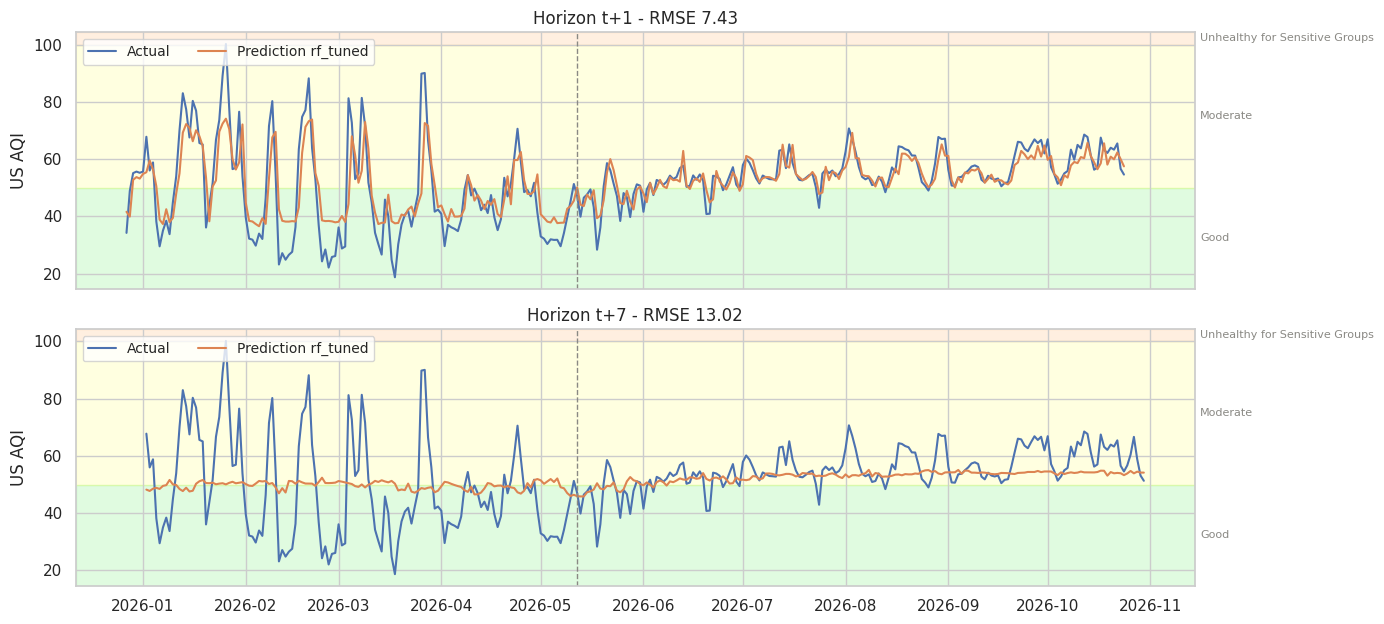

In [58]:
def plot_prediction_comparison(long: pd.DataFrame, model_name: str, horizons=(1, HORIZON)) -> plt.Figure:
    """Plot actual vs predicted AQI over the evaluation period, one panel per horizon."""
    fig, axes = plt.subplots(len(horizons), 1, figsize=(14, 3.2 * len(horizons)), sharex=True, squeeze=False)
    upgrade = pd.Timestamp(CAMS_UPGRADES["post_cams_50r1"])
    for ax, h in zip(axes.ravel(), horizons):
        rows = long.loc[(long["model"] == model_name) & (long["horizon"] == h)].set_index("target_date")
        frame = rows[["y_true", "y_pred"]].rename(columns={"y_true": "Actual", "y_pred": f"Prediction {model_name}"})
        rmse = root_mean_squared_error(rows["y_true"], rows["y_pred"])
        plot_line(frame, title=f"Horizon t+{h} - RMSE {rmse:.2f}", ylabel="US AQI", ax=ax, marker=None)
        ax.axvline(upgrade, color=COLOR_MUTED, ls="--", lw=1)
        shade_aqi_categories(ax)
    fig.tight_layout()
    return fig


def residual_frame(long: pd.DataFrame, model_name: str, horizons=(1, 4, HORIZON)) -> pd.DataFrame:
    """Residuals (actual − prediction) per horizon, indexed by a continuous daily target date."""
    rows = long.loc[(long["model"] == model_name) & long["horizon"].isin(horizons)]
    wide = rows.pivot(index="target_date", columns="horizon", values="residual")
    return wide.rename(columns=lambda h: f"residual_t+{h}").asfreq("D")



fig = plot_prediction_comparison(pred_long, BEST_MODEL)
fig.savefig(FIG_DIR / "actual_vs_prediction.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

**Insight: actual vs. predicted.**

* **Day-ahead (t+1).** The forecast follows the day-to-day level closely, especially after
  mid-May 2026, when the series becomes calmer.
* **Compressed extremes.** During the volatile January–March 2026 period, peaks of AQI 80–100 are
  under-predicted by roughly 20–30 points, and troughs of 20–30 are over-predicted. This pull towards
  the mean is typical of tree ensembles, which average over similar past days.
* **Week-ahead (t+7).** The forecast is almost flat, between about 48 and 55. It behaves like a
  seasonal average and cannot anticipate individual episodes a week in advance.
* **After the CAMS 50r1 upgrade (dashed line).** Errors shrink because the series is less volatile.
  However, from August 2026 the actual AQI drifts up to 60–68 while the week-ahead forecast stays
  near 55.

### 7.6 Residual Diagnostics

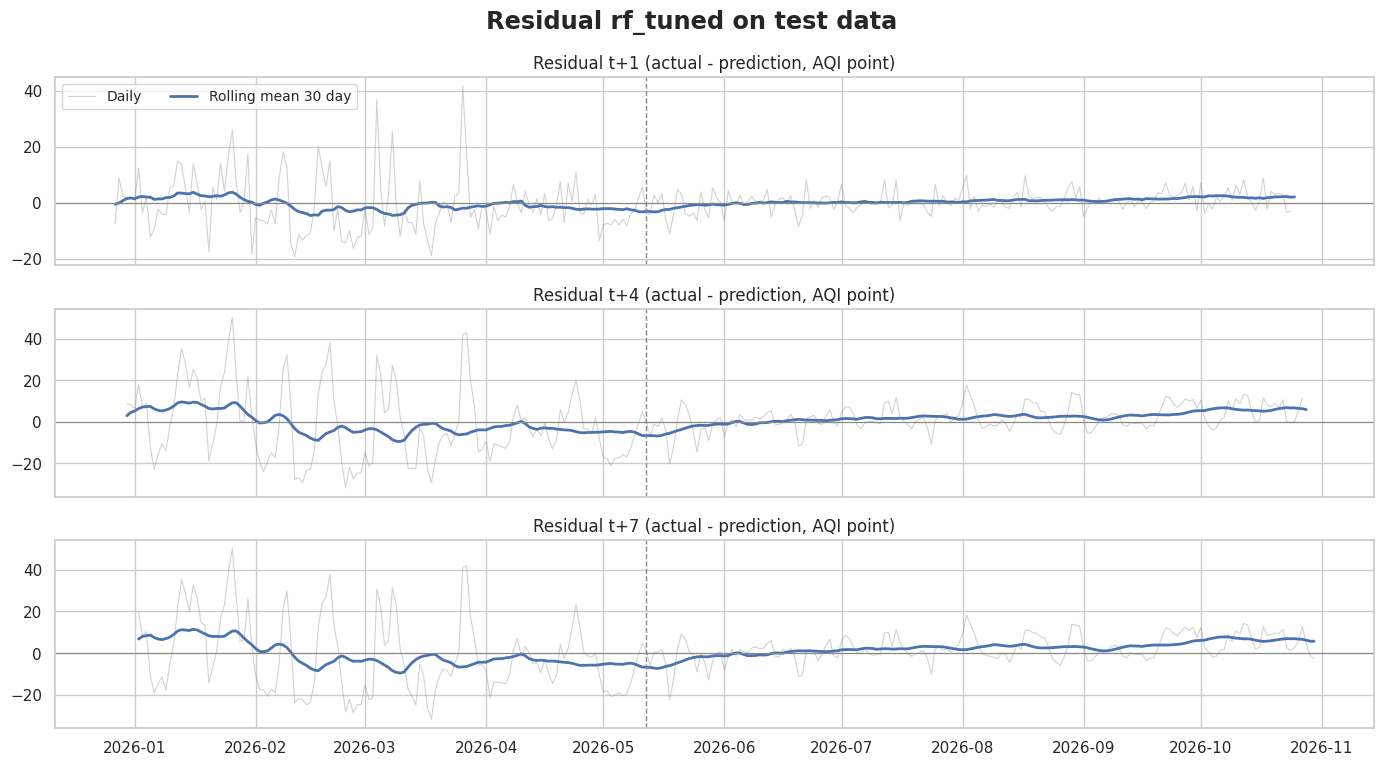

In [59]:
# ===== Residuals over time for horizons t+1, t+4, and t+7 =====
residuals = residual_frame(pred_long, BEST_MODEL)
fig = plot_small_multiples(
    residuals,
    {col: f"Residual {col.split('_')[1]} (actual - prediction, AQI point)" for col in residuals},
    suptitle=f"Residual {BEST_MODEL} on {EVAL_SPLIT} data",
)
for ax in fig.axes:
    ax.axhline(0, color=COLOR_MUTED, lw=0.8)
    ax.axvline(pd.Timestamp(CAMS_UPGRADES["post_cams_50r1"]), color=COLOR_MUTED, ls="--", lw=1)
fig.savefig(FIG_DIR / "residuals.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

**Insight: residuals over time.**

* **Unbiased on average.** At t+1, the 30-day mean residual stays within about ±4 AQI points across
  the whole test period.
* **Largest errors during episodes.** The largest residuals, up to +40 and −30, occur in the
  January–March 2026 episodes.
* **Errors grow with the horizon.** The spread widens markedly from t+1 to t+4 and then stays
  similar to t+7. At the longer horizons, the 30-day mean residual swings between about −10 and
  +11.
* **Recent systematic under-prediction.** From August to October 2026, the t+4 and t+7 residuals
  turn consistently positive (+5 to +8). The model under-predicts the recent upward drift that was
  also visible in the deseasonalised series (Section 4.5.5).

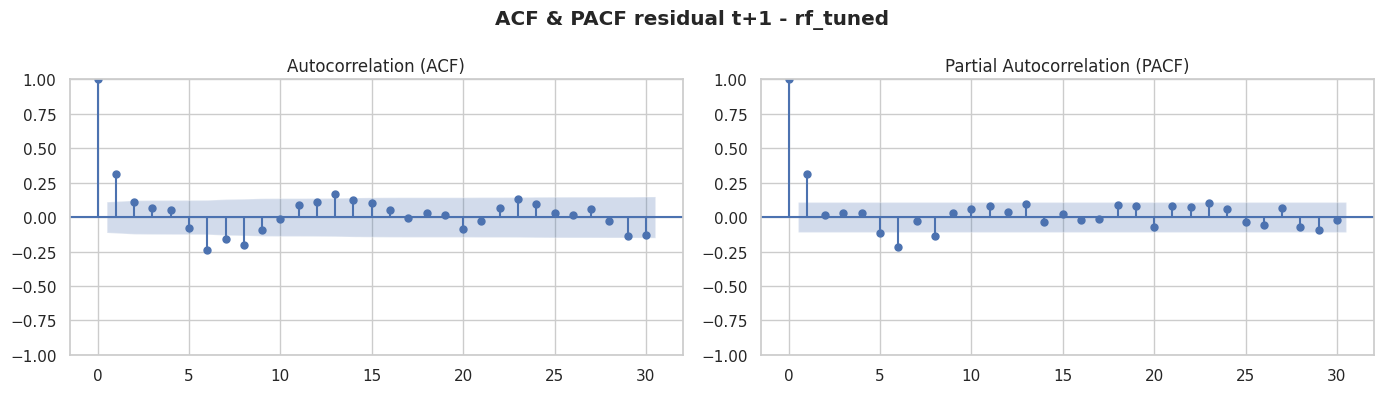

In [60]:
# ===== Residual autocorrelation (t+1) =====
fig = plot_acf_pacf(residuals["residual_t+1"], lags=30,
                    title=f"ACF & PACF residual t+1 - {BEST_MODEL}")
fig.savefig(FIG_DIR / "residual_acf_pacf.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

**Insight: residual autocorrelation (t+1).**

* **Lag 1 is significant.** The ACF and PACF at lag 1 (≈0.31) lie clearly outside the confidence
  band. Lag 2 (≈0.11) is at the edge, and lag 3 lies inside.
* **A weekly echo.** Moderate negative values at lags 6–8 (ACF down to ≈−0.24) suggest a weak
  weekly echo in the errors.

Remaining autocorrelation means that recent errors still carry information. An error-correction
step, which adds yesterday's error to today's forecast, or additional lag features could exploit it.

### 7.7 Feature Importance (Test Split)

Permutation importance measures how much the test RMSE (mean over horizons) increases when one
feature is randomly shuffled. Higher values indicate features the model relies on.

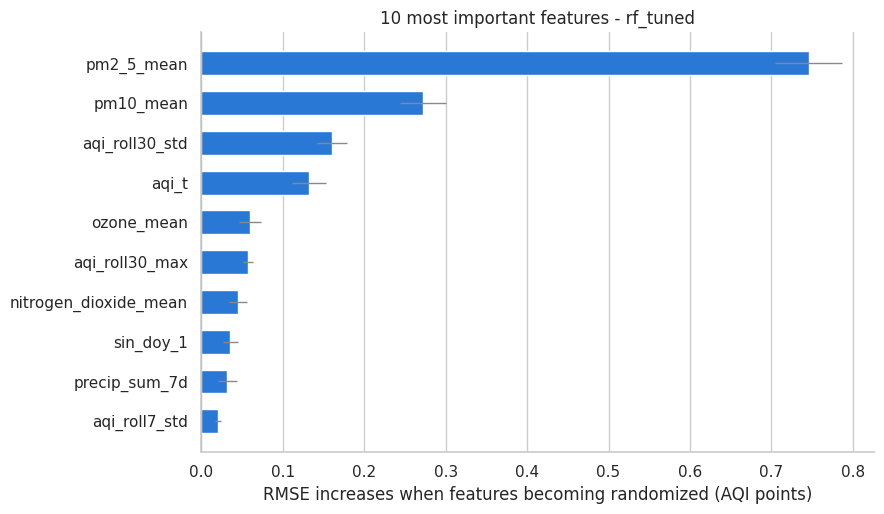

In [61]:
def compute_permutation_importance(model, part: pd.DataFrame, n_repeats: int = 10) -> pd.DataFrame:
    """Permutation importance: RMSE increase (mean over horizons) when one feature is shuffled."""
    X, y, w = to_tabular(part)
    result = permutation_importance(model, X, y, sample_weight=w, n_repeats=n_repeats,
                                    scoring="neg_root_mean_squared_error", random_state=SEED, n_jobs=-1)
    return (pd.DataFrame({"importance": result.importances_mean, "std": result.importances_std},
                         index=SELECTED_FEATURES).sort_values("importance", ascending=False))


def plot_feature_importance(importance: pd.DataFrame, model_name: str, top_n: int = 10) -> plt.Figure:
    """Horizontal bar chart of the top-N permutation importances with standard-deviation bars."""
    top = importance.head(top_n).iloc[::-1]
    fig, ax = plt.subplots(figsize=(9, 0.38 * len(top) + 1.5))
    ax.barh(top.index, top["importance"], xerr=top["std"], color=COLOR_PRED, height=0.6,
            error_kw={"ecolor": COLOR_MUTED, "lw": 1})
    ax.axvline(0, color=COLOR_MUTED, lw=0.8)
    ax.set(title=f"{top_n} most important features - {model_name}",
           xlabel="RMSE increases when features becoming randomized (AQI points)")
    ax.grid(axis="y", visible=False)
    ax.spines[["top", "right"]].set_visible(False)
    fig.tight_layout()
    return fig


importance = compute_permutation_importance(models[BEST_MODEL], eval_part)
importance.to_csv(ARTIFACT_DIR / f"feature_importance_{BEST_MODEL}.csv")
fig = plot_feature_importance(importance, BEST_MODEL)
fig.savefig(FIG_DIR / "feature_importance.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

**Insight: feature importance.**

* **Top three features.** `pm2_5_mean` (≈0.75 AQI points of RMSE increase when shuffled),
  `pm10_mean` (≈0.27), and `aqi_roll30_std` (≈0.16, the 30-day volatility of the AQI). They are
  followed by `aqi_t` (≈0.13), `ozone_mean`, `aqi_roll30_max`, and `nitrogen_dioxide_mean`.
* **Particulates dominate.** PM2.5 dominates, as in the validation probe (Section 5.3). On the test
  period, however, PM10 and the AQI history carry more weight.
* **A volatile month is a warning sign.** The model relies on recent AQI volatility, so a
  turbulent past month signals a higher chance of further swings.
* **Weather plays a minor role.** The only weather feature in the top ten is the 7-day rainfall sum
  (`precip_sum_7d`, ≈0.03). This is consistent with the weak direct correlations in Section 4.5.4.

As in Section 5.3, correlated features share credit, so the importance of AQI lags and PM2.5 should
be read together.

### 7.8 Assessment against Business and Data-Mining Success Criteria

| ID | Criterion (Section 2.4) | Evidence | Status |
|---|---|---|---|
| B1 | Consolidated view of air quality | Baseline KPIs and seasonal risk windows (4.5.2, 4.5.5); clean daily dataset exported for the dashboard | Achieved |
| B2 | Targeted mitigation | Variable ranking (4.5.4), feature importance (7.7), and early-warning signals (9.5) | Achieved |
| B3 | Proactive advisories | Category accuracy 76.96% vs. 72.47% for the best benchmark, persistence (7.4) | Achieved |
| D1 | Baseline KPIs | Annual KPI table (4.5.2) | Achieved |
| D2 | Association ranking | Spearman matrix (4.5.4) and permutation importance (7.7) | Achieved |
| D3 | Model selection | CV leaderboard (6.5): `rf_tuned`, CV RMSE 9.32 | Achieved |
| D4 | Beats naive benchmarks | Success-criteria check (7.4): RMSE 11.83 vs. 13.65; MAE 8.37 vs. 9.98 | Achieved |
| D5 | sMAPE ≤ 15% | Success-criteria check (7.4): sMAPE 16.79% (met only at t+1: 10.39%) | **Not achieved** |

**Seven of eight criteria are met.** The one gap, D5, reflects week-ahead accuracy rather than the
short-range forecasts that matter most for advisories.

### 7.9 Review of the Process

**What worked**

* Leakage safeguards (causal features, embargo, train-only fitting) held throughout the pipeline.
* The test split was used once, after model selection on walk-forward CV.
* Seeds, a data-version hash, and exported artifacts make every result traceable.

**What should be revisited in the next iteration**

* **Success criterion.** The accuracy criterion was changed from MAPE to sMAPE after preliminary
  results were available. All criteria should be fixed before modelling.
* **Search spaces.** Several tuned hyperparameters lie on the edge of their ranges, so the ranges
  should be widened.
* **Tuning reproducibility.** On a re-run within the same session, the Optuna journal file appends
  new trials to the previous study. It should be deleted for exactly reproducible tuning.
* **Seasonal terms.** The AIC favours three or four Fourier harmonics over the two that are used.
* **Week-ahead skill.** Beyond t+3 the forecast converges to a seasonal average (Section 7.4).
  Future weather inputs and an error-correction step (Section 7.6) are the most promising fixes.
* **Data quality.** The 2023 SO₂ step and the negative concentrations in the raw data should be
  clarified with the data provider.

### 7.10 Decision on Next Steps

| Outcome | Decision |
|---|---|
| All business and data-mining criteria are met | Approve the model to support daily advisories |
| B3, D3, and D4 are met, but D5 (sMAPE ≤ 15%) is missed | Approve the model as decision support under supervision, and run one more iteration (Section 7.9) before full adoption |
| Either naive benchmark is not beaten (D4 missed) | Do not adopt the model; return to Data Preparation and Modeling |

**Decision: approve `rf_tuned` as supervised decision support, and run one more iteration before
full adoption** (second row of the table).

**Rationale**

* **The model is useful.** It beats both naive benchmarks on RMSE (−27.9% vs. persistence, −13.3%
  vs. climatology) and on MAE (D4). It also places more forecasts in the correct AQI category than
  any benchmark (76.96% vs. 72.47%; B3).
* **It is not yet accurate enough to run on its own.** The mean sMAPE of 16.79% misses the 15%
  target (D5). Accuracy drops sharply after day 3.

**Conditions of use**

1. **Days 1–3 are actionable.** They have category accuracy of 78–90% and RMSE of 7.4–12.5, so
   advisories should be based on them. Days 4–7 should be communicated as an *outlook* only.
2. **A human stays in the loop.** An analyst at the health service or DLH confirms every advisory
   before it is published.
3. **Retrain on schedule.** Retrain monthly and after every CAMS upgrade, and track live category
   accuracy (Section 9.5, recommendation 6).

**Exit criteria for the next iteration**

* Mean test sMAPE ≤ 15% on a fresh, pre-registered test period.
* Category accuracy at t+4 to t+7 above the persistence benchmark.

The priority improvements are those listed in Section 7.9: future weather inputs, an
error-correction step, wider search spaces, and three or four Fourier harmonics.

## 8. Forecasting and Export

### 8.1 Refit on the Full History

Once evaluation is complete, the selected configuration is retrained on every labelled row: train,
validation, embargo, and test. The forecast then reflects the most recent data, including the
CAMS 50r1 regime.

In [62]:
# ===== Refit the selected model on the full history =====
# Evaluation is complete, so the selected configuration is retrained on every labelled row
# (train, validation, embargo, and test) to capture the most recent regime before forecasting.
selected = candidates[BEST_MODEL]
X_full, y_full, w_full = to_tabular(df_model)
final_model = fit_model(MODEL_SPECS[selected.spec_name], selected.params, X_full, y_full, w_full)
save_model(final_model, f"{BEST_MODEL}_final", model_params(final_model))
print(f"Final model: {BEST_MODEL} refit on {len(X_full)} rows "
      f"({X_full.index[0].date()} to {X_full.index[-1].date()})")

Final model: rf_tuned refit on 1512 rows (2022-09-03 to 2026-10-23)


### 8.2 Seven-Day Forecast

The forecast starts from the most recent day with complete features. The uncertainty band adds the
10th and 90th percentiles of the test-period residuals for each horizon to the point forecast. The
band therefore reflects realised out-of-sample errors rather than model assumptions.

      date  horizon  aqi_pred  aqi_low  aqi_high category
2026-10-31        1      54.0     46.1      61.2 Moderate
2026-11-01        2      54.2     40.7      64.8 Moderate
2026-11-02        3      54.6     38.6      67.1 Moderate
2026-11-03        4      55.5     38.1      68.7 Moderate
2026-11-04        5      55.9     38.7      69.3 Moderate
2026-11-05        6      55.9     38.5      69.8 Moderate
2026-11-06        7      55.6     37.9      69.4 Moderate


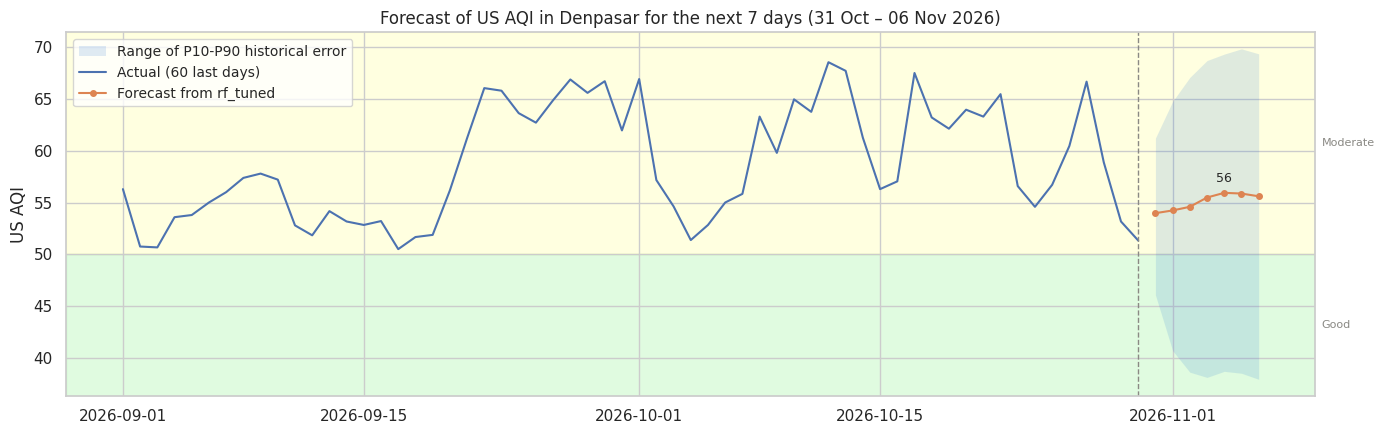

In [63]:
def forecast_next_days(model, df: pd.DataFrame, residuals: pd.DataFrame) -> pd.DataFrame:
    """Forecast the next H days from the latest available day.

    The P10–P90 band adds per-horizon quantiles of historical residuals
    (actual − prediction on the evaluation split) to the point forecast.
    """
    latest = build_features(df)[SELECTED_FEATURES].iloc[[-1]]
    if latest.isna().any(axis=None):
        raise ValueError("Features for the latest day are incomplete; check the most recent data.")
    pred = predict_model(model, latest).iloc[0].to_numpy()
    quantiles = residuals.groupby("horizon")["residual"].quantile([0.1, 0.9]).unstack()
    steps = np.arange(1, HORIZON + 1)
    return pd.DataFrame({
        "date": latest.index[0] + pd.to_timedelta(steps, unit="D"),
        "horizon": steps,
        "aqi_pred": pred,
        "aqi_low": pred + quantiles.loc[steps, 0.1].to_numpy(),
        "aqi_high": pred + quantiles.loc[steps, 0.9].to_numpy(),
    }).assign(category=lambda d: pd.cut(d["aqi_pred"], bins=AQI_BINS, labels=AQI_LABELS, include_lowest=True))


def plot_forecast(history: pd.Series, forecast: pd.DataFrame, model_name: str) -> plt.Figure:
    """Plot recent actual AQI with the H-day forecast and its historical error band."""
    fig, ax = plt.subplots(figsize=(14, 4.5))
    ax.fill_between(forecast["date"], forecast["aqi_low"], forecast["aqi_high"], color=COLOR_PRED,
                    alpha=0.15, lw=0, label="Range of P10-P90 historical error")
    plot_line(history.rename(f"Actual ({len(history)} last days)"), title="", ax=ax, marker=None)
    plot_line(forecast.set_index("date")["aqi_pred"].rename(f"Forecast from {model_name}"),
              ylabel="US AQI", ax=ax, marker="o",
              title=f"Forecast of US AQI in Denpasar for the next {HORIZON} days "
                    f"({forecast['date'].iloc[0]:%d %b} – {forecast['date'].iloc[-1]:%d %b %Y})")
    ax.axvline(history.index[-1], color=COLOR_MUTED, ls="--", lw=1)
    peak = forecast.loc[forecast["aqi_pred"].idxmax()]
    ax.annotate(f"{peak['aqi_pred']:.0f}", (peak["date"], peak["aqi_pred"]), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=9)
    shade_aqi_categories(ax)
    fig.tight_layout()
    return fig


# The P10–P90 band uses test-split residuals of the same configuration (trained on train + val),
# which approximates the out-of-sample error of the refit model.
best_residuals = pred_long.loc[pred_long["model"] == BEST_MODEL]
forecast = forecast_next_days(final_model, df_clean, best_residuals)
forecast.to_parquet(DATA_DIR / "forecast_latest.parquet")
print(forecast.round({"aqi_pred": 1, "aqi_low": 1, "aqi_high": 1}).to_string(index=False))

fig = plot_forecast(df_clean[TARGET].iloc[-HISTORY_DAYS:], forecast, BEST_MODEL)
fig.savefig(FIG_DIR / "forecast_7d.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()

**Insight: 7-day forecast.**

* **The coming week.** For 31 October – 6 November 2026, the forecast ranges from 54.0 to 55.9, and
  every day falls in the *Moderate* category.
* **Uncertainty grows with the horizon.** The P10–P90 band spans about 15 AQI points at t+1 (46.1 to
  61.2) and widens to about 31 points at t+7 (37.9 to 69.4).
* **No advisory needed.** The highest upper band (69.8) stays well below AQI 100, so neither tier of
  the early-warning rule in Section 9.5 is triggered.

The forecast also sits slightly above the late-October readings, in line with the recent upward
drift noted in Section 7.6.

### 8.3 Export for the Dashboard

Predictions of every candidate over all splits are exported in long format, together with metrics
grouped by split, horizon, and CAMS 50r1 regime. They use the same metric functions as Section 7, so
the dashboard can display model performance and regime effects consistently with the notebook.

In [64]:
# Export predictions over all splits and regime-aware metrics for every candidate
for name, model in models.items():
    export_predictions(predict_model(model, df_model), name)
print("Exported predictions and metrics:", ", ".join(models))

Exported predictions and metrics: gb_baseline, rf_baseline, gb_tuned, rf_tuned


## 9. Conclusion and Recommendations

### 9.1 Conclusion Based on Evaluation Results

**In one sentence:** Denpasar's air is moderate on most days, its worst days follow recognisable
conditions, and a 7-day forecast turns that knowledge into advance warning.

* **Air quality baseline (Goal 1).** Between August 2022 and October 2026, the city's air was
  persistently *Moderate*: the annual mean AQI stayed between 50.6 and 52.9, with no trend. Only
  5 days (0.3%) exceeded AQI 100, all between November and February. The dry and wet seasons differ
  by just 1 point on average. Fine particles
  are the main concern: mean PM2.5 (11.0 µg/m³) is more than twice the WHO annual guideline (World
  Health Organization, 2021).
* **What drives bad days (Goal 2).** PM2.5 tracks the AQI most closely (ρ = 0.91), followed by PM10
  and O₃.
  * Rain cleans the air, with diminishing returns.
  * Wind mainly disperses combustion gases such as NO₂ and CO.
  * Temperature shows no clear link in this data, unlike the negative correlation reported for
    particulates during Nyepi (Nuraini et al., 2019).

  Together, these findings support the local evidence that human activity sets the pollution load
  and the weather decides how much of it lingers (Nuryanto et al., 2024).
* **Forecasting (Goal 3).** The tuned Random Forest, chosen on walk-forward CV, forecasts the next
  seven days with a test RMSE of 11.83, an MAE of 8.37, and an sMAPE of 16.79%.
  * Naive benchmarks (D4): it **beats both**, with an RMSE 27.9% lower than persistence and 13.3%
    lower than climatology.
  * sMAPE target of 15% (D5): it **misses the target**, which is met only for the next day
    (10.39%).
  * AQI category accuracy (B3): 76.96% of forecasts fall in the correct category, against 72.47% for
    the best benchmark.
  * The forecast is most reliable for the first three days (category accuracy 78–90%). The model is
    approved as supervised decision support, with one more improvement iteration planned
    (Section 7.10).
* **Reliability depends on data stewardship.** CAMS model upgrades shift several pollutant levels,
  and a structural break falls inside the test period. Model-based air quality data also carry
  known surface biases (Lacima et al., 2023), so regular retraining and validation against ground
  stations are prerequisites for operational use.

### 9.2 Were the Problem Statements Addressed?

1. **Problem Statement 1, a consolidated view of air quality: addressed** [B1, D1].
   The baseline KPIs (Section 4.5.2), the trend and seasonal analyses, and the dashboard export
   give stakeholders a single, consistent picture. Two risk windows are now explicit:
   * a mild late-dry-season rise, peaking in September;
   * short, sharp episodes in November–February, when all five days above AQI 100 occurred.
2. **Problem Statement 2, quantified drivers: addressed** [B2, D2].
   The Spearman ranking and the LOWESS curves quantify which pollutants and weather conditions move
   with the AQI. Permutation importance (PM2.5, PM10, and the 30-day AQI volatility) confirms which variables the
   forecasting model relies on.
3. **Problem Statement 3, a short-term forecast: partially addressed** [B3, D3–D5].
   A 7-day forecast with uncertainty bands and AQI categories is available, and it beats both naive
   benchmarks. It is reliable for the first three days but misses the sMAPE target over the full
   week. Random Forest edged out Gradient Boosting on walk-forward CV (9.32 vs. 9.40). The gap is
   small enough to call the bagging-versus-boosting question a practical tie.

### 9.3 Were the Goals Achieved?

The goal-level summary below condenses the criterion-level assessment in Section 7.8.

| Goal | Criteria (Section 2.4) | Result | Status |
|---|---|---|---|
| 1. Air quality baseline | B1, D1 | Annual mean AQI 50.6–52.9, no trend; 5 days above 100 (0.3%); dry 52.4 vs. wet 51.3 | Achieved |
| 2. Key variables | B2, D2 | PM2.5 ρ = 0.91, PM10 0.80, O₃ 0.64; rain duration −0.25; top model features PM2.5, PM10, 30-day AQI volatility | Achieved |
| 3. Reliable 7-day forecast | B3, D3, D4, D5 | `rf_tuned`; RMSE 11.83 vs. 13.65 and MAE 8.37 vs. 9.98 (best benchmark); sMAPE 16.79%; category accuracy 76.96% vs. 72.47% | Partially achieved (D5 missed) |

### 9.4 Did the Solution Approach Deliver Meaningful Impact?

* **From reactive to proactive.** More than 37,000 hourly records are condensed into a handful of
  KPIs and seasonal risk windows that a non-specialist can read in minutes. The dashboard export
  puts them in front of decision-makers.
* **Earlier warnings, fewer missed spikes.** The forecast gives health services and city agencies
  up to **3 days of actionable lead time**, with category accuracy of 78–90%, instead of reacting
  once the AQI has already deteriorated. Across all seven days, 76.96% of forecasts land in the
  correct AQI category, which shows how often an advisory based on the forecast would match the
  observed category. This addresses the cost asymmetry set out in Section 2.3: a
  missed spike costs more than an unnecessary advisory.
* **Trustworthy by design.** The following safeguards make the results reproducible and auditable,
  a prerequisite for use in public decision-making:
  * leakage-safe features;
  * an embargoed chronological split;
  * CV-based model selection with a single test evaluation;
  * versioned artifacts.

### 9.5 Recommendations (Prescriptive Actions)

Each recommendation names the stakeholder best placed to act (see Section 2.3).

1. **Target PM2.5 at its local sources.** *Owner: the city and provincial environment agencies
   (DLH).*
   PM2.5 drives the AQI and stays above the WHO guideline throughout the period. Priority sources
   are:
   * open waste burning, which increased after the Suwung landfill closure (Erviani, 2026);
   * landfill fires such as the October 2023 Suwung fire (Rhismawati, 2023a);
   * traffic and construction dust.

   Nyepi shows how quickly the air responds when these activities stop (Nuryanto et al., 2024).
2. **Adopt a two-tier early-warning rule.** *Owner: health services (Dinas Kesehatan) together
   with DLH.*
   * **Tier 1:** issue a public advisory when the forecast, or its P90 band, exceeds AQI 100 within
     the next three days.
   * **Tier 2:** raise the alert level when such a forecast coincides with dry conditions (no rain
     for three or more days) and weak wind (below about 15 km/h). The EDA shows the highest AQI
     under these conditions.
3. **Prepare for two risk windows.** *Owner: the city government and DLH.*
   * **August–October.** Schedule waste-burning inspections, roadside emission checks, and dust
     control on construction sites for this period, ahead of the mild September peak in the
     seasonal baseline.
   * **November–February.** Keep rapid-response capacity on standby (fire crews for landfill fires,
     open-burning patrols, public messaging). All five days above AQI 100 fell in this window.
4. **Communicate daily, not monthly.** *Owner: health services and tourism operators.*
   Pollution spikes last only a few days, so residents and visitors need daily updates through the
   dashboard and messaging channels.
5. **Anchor the model to ground truth.** *Owner: DLH with the project data team.*
   Compare the CAMS-based estimates with measurements reported under the national Air Pollutant
   Standard Index framework, ISPU (Kementerian Lingkungan Hidup dan Kehutanan, 2020). Studies of
   CAMS products report persistent surface biases, and show that bias correction with in situ
   measurements substantially improves PM2.5 forecasts (Lacima et al., 2023; Wu et al., 2020).
6. **Operationalise and maintain the model.** *Owner: the project data team.*
   * Refresh the forecast daily.
   * Retrain at least monthly, and after every CAMS upgrade.
   * Track live category accuracy to detect drift early.

### 9.6 Limitations and Future Work

Process-related findings are listed in Section 7.9. The limitations below concern the data and the scope of the analysis.

* **Model-based input data.** CAMS estimates can shift when the model is upgraded (November 2024,
  May 2026), and global reanalyses show persistent biases at ground level (Lacima et al., 2023).
  The 2023 SO₂ step remains unexplained.
* **Short history.** About four years of data cover only four annual cycles, which limits the
  seasonal modelling. The AIC suggests that three or four Fourier harmonics would fit better than
  two.
* **No future weather inputs.** The features use weather observed on day t only. Adding numerical
  weather forecasts for t+1 … t+7 would likely improve longer horizons, where the current forecast
  converges to a seasonal average (Section 7.4).
* **Few extreme days to learn from.** Only 5 days exceeded AQI 100, so the model under-predicts
  spikes by design (Section 7.5). Episode-focused methods, such as quantile models or a dedicated
  spike classifier, are a natural extension.
* **Driver scope.** Dominant-pollutant shares based on EPA sub-indices, and anthropogenic variables
  such as traffic, tourist arrivals, or waste-burning reports, are not part of this analysis. They
  are natural next steps for source-specific mitigation.
* **Empirical uncertainty bands.** The P10–P90 band is estimated from test residuals of the model
  trained on train + validation. It approximates, rather than guarantees, the coverage of the refit
  model.

---
*End of notebook.*